# Müşteri ayrılması: soru odaklı EDA

Ana soru: **Sınırlı kapasiteyle hangi müşterilere bakarsak ayrılanların en büyük kısmını yakalarız?**

Kapsam: tüm 10.000 müşteri, betimsel. Her bölüm: Soru → yöntem gerekçesi → tablo + grafik → kısa yorum → sınır. Bölüm 0–6 tamamlandı. Yönetici özeti için Bölüm 6c'ye bakın.

**28 Ekim yorum revizyonu:** Gözlem, iş anlamı ve sınırlar güncellendi. Sayısal analiz ve kayıtlı tablolar/grafikler yeniden çalıştırılmadı. Tarihsel “Fark yok/Güven” etiketleri eşitlik veya kesinlik kanıtı değildir. ML değerlendirmesinin sınırları doğrudan `02_ml.ipynb` yorumlarında açıklanır; model/eğitim/seçim kodu ve kayıtlı çıktılar korunur.

## 0. Kurulum

**Soru:** Doğru ortam ve doğru veri mi?

**Yöntem ve gerekçe:** Sonuçların `.venv` (Python 3.12.14, NumPy 2.2.6) ile tekrarlanabilir olması ve 10.000 müşterinin eksiksiz yüklenmesi gerekir. Beklenen: 10.000 müşteri, 2.037 ayrılan, %20,37.

**Sınır:** SQL kalite özeti tablosu bu bölüme eklenecek.

In [1]:
from pathlib import Path
import platform, sys
import numpy as np
import pandas as pd
from IPython.display import display

# CSV'yi bulmak için çalışma klasöründen yukarı doğru çıkılır (arşiv alt klasöründe de çalışır).
working_dir = Path.cwd().resolve()
project_root = next(
    (f for f in (working_dir, *working_dir.parents) if (f / "Churn_Modelling.csv").is_file()), None
)
if project_root is None:
    raise FileNotFoundError("Proje klasörünü veya notebooks klasörünü açın.")
if str(project_root / "src") not in sys.path:
    sys.path.insert(0, str(project_root / "src"))

from churn_analysis import eda

print("Python:", platform.python_version(), "| NumPy:", np.__version__, "| pandas:", pd.__version__)
print("Beklenen: Python 3.12.14, NumPy 2.2.6 (.venv çekirdeği)")

eda.stil_uygula()
veri = eda.hazirla(pd.read_csv(project_root / "Churn_Modelling.csv"))
genel_oran = veri["Exited"].mean()
cikti_klasoru = project_root / "reports" / "eda"
print(f"Müşteri: {eda.tr_sayi(len(veri))} | Ayrılan: {eda.tr_sayi(veri['Exited'].sum())} | Oran: %{eda.tr_sayi(100 * genel_oran, 2)}")

Python: 3.12.14 | NumPy: 2.2.6 | pandas: 3.0.6
Beklenen: Python 3.12.14, NumPy 2.2.6 (.venv çekirdeği)
Müşteri: 10.000 | Ayrılan: 2.037 | Oran: %20,37


## 1. Veri profili

**Soru:** Hangi dağılım özellikleri sonraki oranların yorumunu etkiler?

**Yöntem ve gerekçe:** Her değişkene aynı beş kontrol uygulanır: tek değerde yığılma (en sık değerin payı), uçta yığılma (min/maks sıklığı), seyrek kategori (n < 100), çarpıklık/IQR dışı sayı ve şekil. Amaç her değişkeni çizmek değil, *yorumu değiştirecek* özellikleri bulmaktır; örneğin sıfırda yığılan bakiyede ortalama yanıltıcıdır. Sorun çıkmayan ikili değişkenler (ülke, cinsiyet, kart, aktiflik) tabloda bir satır olarak kalır, grafik almaz. Uç değerler işaretlenir, silinmez; pasta grafik kullanılmaz.

**Sınır:** Dağılım gözlemleri nedensellik veya gerçek bir bankaya genelleme değildir; düz maaş ve eşit Tenure dağılımı verinin yapay üretilmiş olabileceğini düşündürür.

In [2]:
profil = eda.profil_tablosu(veri)
display(profil.round(2))

,Tür,Farklı değer,Min,Medyan,Ortalama,Maks,Çarpıklık,En sık değer,En sık değer payı (%),Min'de n,Maks'ta n,IQR dışı n,n<100 grup
Değişken,,,,,,,,,,,,,
Kredi puanı,Sürekli,460,350.00,652.00,650.53,850.00,-0.07,850,2.33,5.0,233.0,15.0,0
Yaş,Sürekli,70,18.00,37.00,38.92,92.00,1.01,37,4.78,22.0,2.0,359.0,0
Banka ile ilişki süresi,Kesikli,11,0.00,5.00,5.01,10.00,0.01,2,10.48,413.0,490.0,0.0,0
Bakiye,Sürekli,6382,0.00,97198.54,76485.89,250898.09,-0.14,0.0,36.17,3617.0,1.0,0.0,0
Ürün sayısı,Kesikli,4,1.00,1.00,1.53,4.00,0.75,1,50.84,5084.0,60.0,60.0,1
Tahmini gelir,Sürekli,9999,11.58,100193.92,100090.24,199992.48,0.00,24924.92,0.02,1.0,1.0,0.0,0
Ülke,Kategorik,3,NaN,NaN,NaN,NaN,NaN,Fransa,50.14,NaN,NaN,NaN,0
Cinsiyet,Kategorik,2,NaN,NaN,NaN,NaN,NaN,Erkek,54.57,NaN,NaN,NaN,0
Kredi kartı,Kategorik,2,NaN,NaN,NaN,NaN,NaN,Kartı var,70.55,NaN,NaN,NaN,0


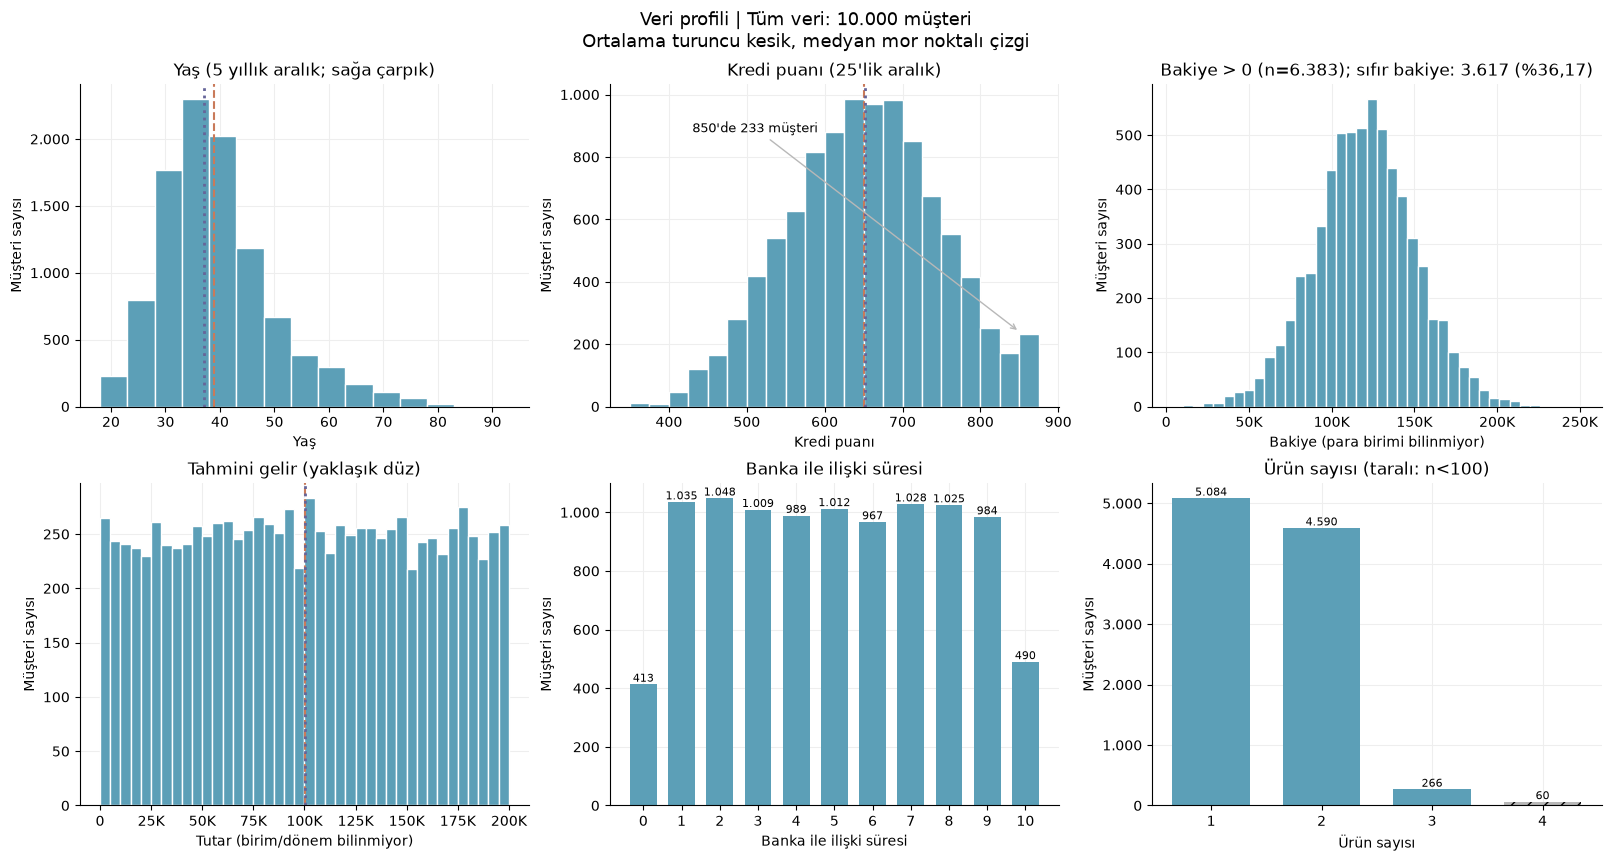

In [3]:
eda.profil_izgarasi(veri, cikti_klasoru);

**Gözlem:** Sıfır bakiye 3.617 müşteride (%36,17) görülüyor; pozitif bakiyeler ayrıca inceleniyor. Müşterilerin %96,74'ü 1–2 ürünlü; 4 ürünlü yalnız 60 müşteri var. Yaş medyanı 37, ortalaması 38,9; 359 kayıt IQR sınırını aşıyor. Kredi puanı 850'de 233 kayıtla yığılıyor. Gelir ve Tenure frekansları görece düzenli.

**İş anlamı:** Sıfır bakiye ile pozitif tutar ayrı okunmalı; seyrek ürün/yaş gruplarında oranla birlikte sayı ve aralık gösterilmeli. Uç gözlemler otomatik silinmez.

**Sınır:** Düzgün dağılımlar verinin yapay olduğunu kanıtlamaz; üretim ve örnekleme süreci belgelenmemiştir. Geography ikili değil, üç kategorilidir. Para/Tenure birimi ve 850 yığılmasının nedeni bilinmiyor.

## 2. Hedefle ilişki

**Soru:** Hangi özellik ayrılanları en çok ayırıyor?

**Yöntem ve gerekçe:** Her grup için aynı ölçüler verilir:

- **n, ayrılan, oran:** Oran tek başına yanıltır; "%100" ile "60 kişinin 60'ı" aynı güveni taşımaz.
- **%95 Wilson güven aralığı:** Oranın ne kadar oynayabileceğini gösterir. Küçük gruplarda ve uç oranlarda klasik formülden daha doğrudur.
- **Lift = grup oranı ÷ genel oran (%20,37):** "Bu grup ortalamanın kaç katı riskli?" sorusunu yanıtlar.
- **Etki büyüklüğü:** Kategoriklerde Cramér's V (0–1), sürekli değişkenlerde AUC (0,5 = ayrım yok).

Testler ölçülerin içinde zaten var: Cramér's V ki-kare testinden, AUC Mann-Whitney U testinden hesaplanır. p-değerleri referans olarak verilir ama **seçim ölçütü değildir**: n = 10.000'de çok küçük farklar da "anlamlı" çıkar; bize farkın büyüklüğü lazım.

**Sınır:** İlişki gösterilir, nedensellik veya teklif etkisi gösterilmez. Değişkenler birbirini karıştırıyor olabilir (ör. Almanya'da sıfır bakiye yok); bu Bölüm 4'te ayrılır. Aralık sınırları tüm veriye bakılarak seçildi; ML'de kullanılırsa yalnızca eğitim verisinde yeniden belirlenir.

### 2a. Kategorik ve kesikli değişkenler

Ülke, cinsiyet, kredi kartı, aktiflik, ürün sayısı, Tenure ve bakiye durumu (sıfır/pozitif). Gri taralı çubuklar n < 100 olan, temkinli okunacak gruplardır.

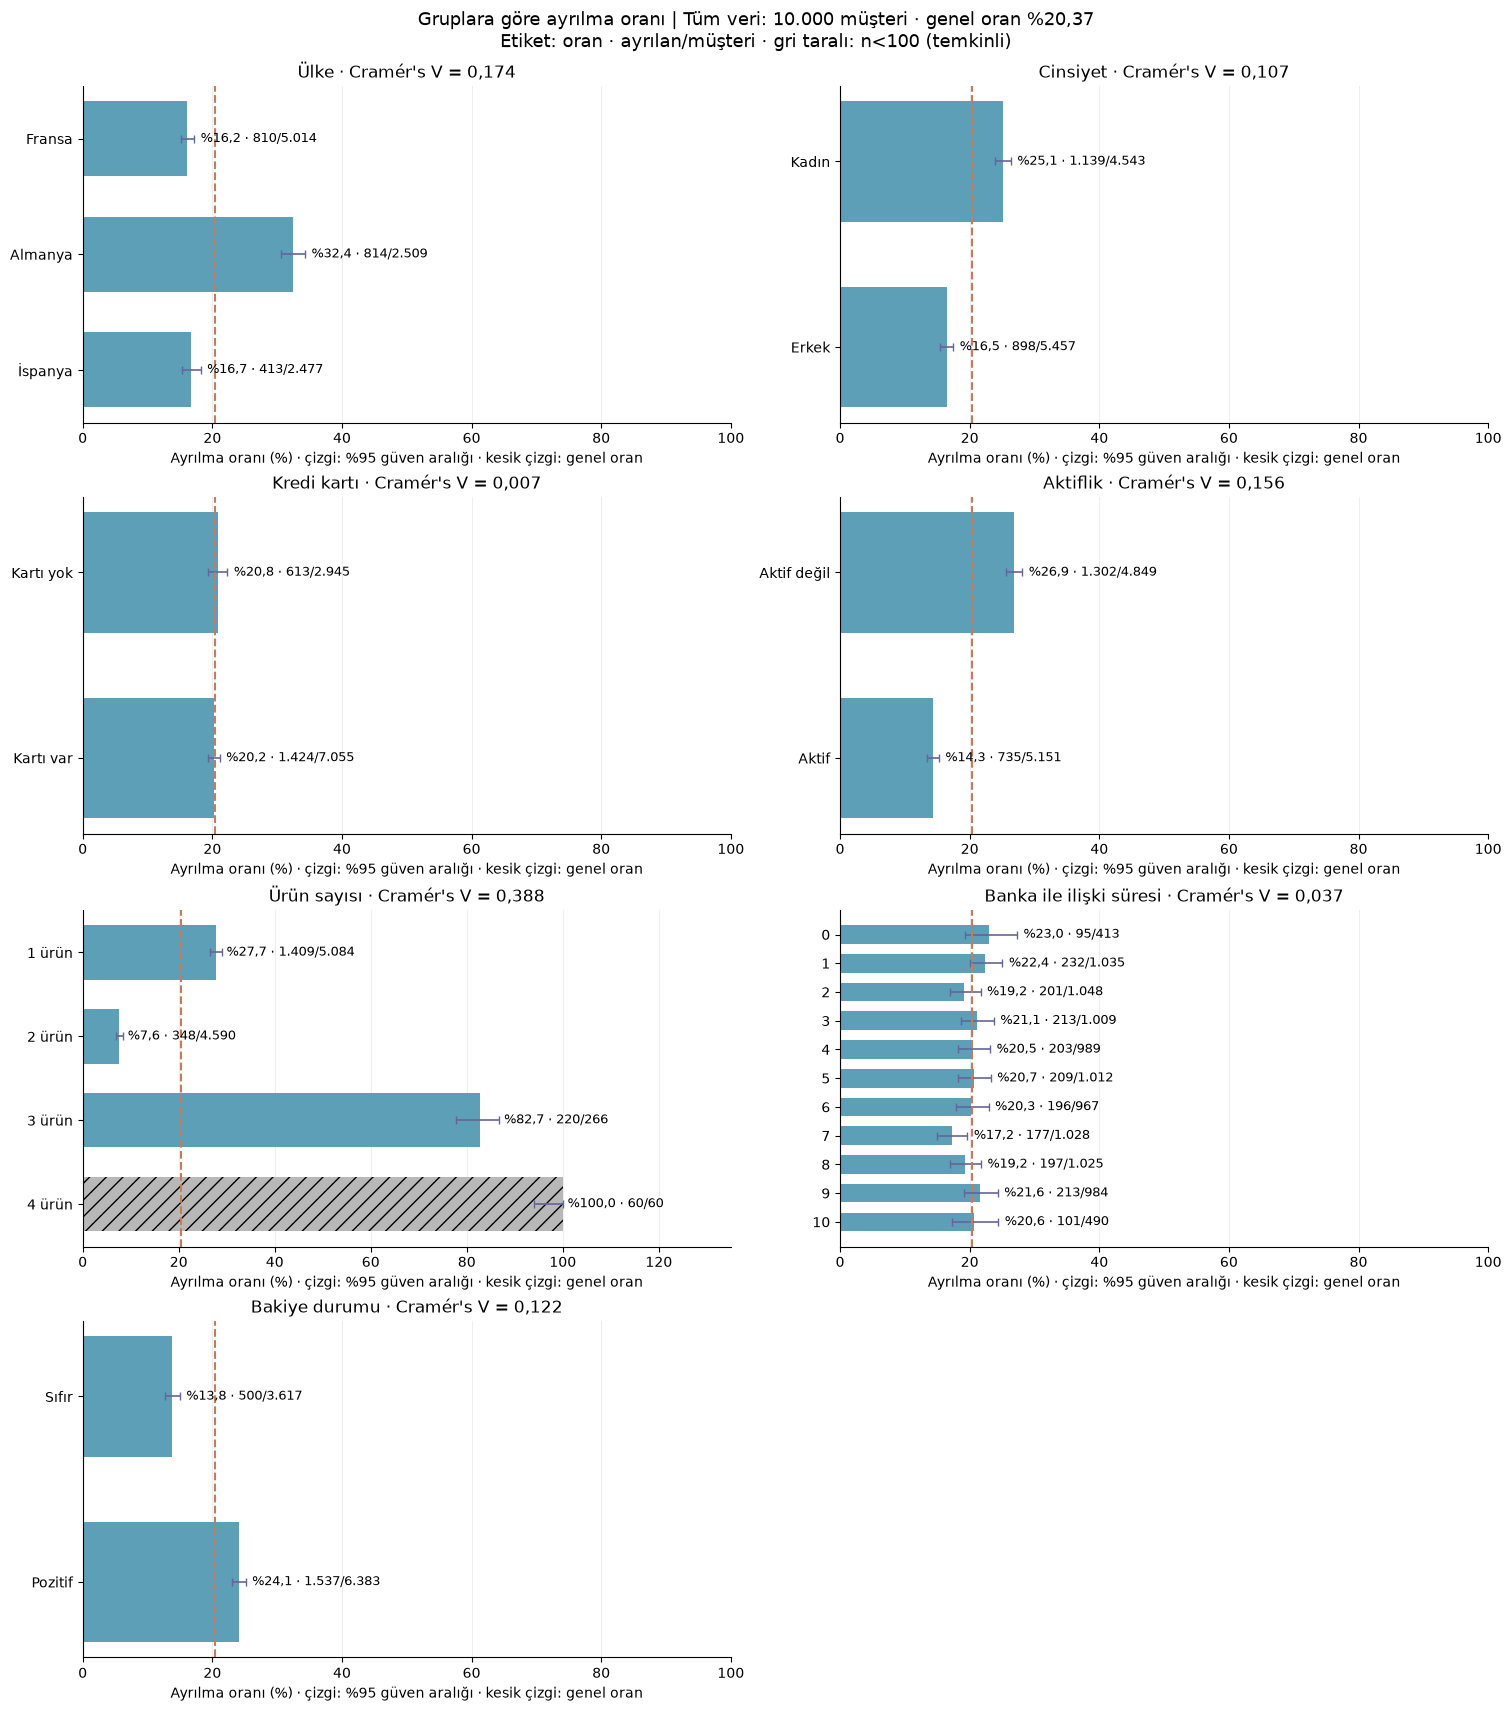

Müşteri sayısı  Ayrılan sayısı  \
Değişken                Grup                                          
Ülke                    Fransa                 5014             810   
                        Almanya                2509             814   
                        İspanya                2477             413   
Cinsiyet                Kadın                  4543            1139   
                        Erkek                  5457             898   
Kredi kartı             Kartı yok              2945             613   
                        Kartı var              7055            1424   
Aktiflik                Aktif değil            4849            1302   
                        Aktif                  5151             735   
Ürün sayısı             1 ürün                 5084            1409   
                        2 ürün                 4590             348   
                        3 ürün                  266             220   
                        4 ürün                   60              60   
Banka ile ilişki süresi 0                       413              95   
                        1                      1035             232   
                        2                      1048             201   
                        3                      1009             213   
                        4                       989             203   
                        5                      1012             209   
                        6                       967             196   
                        7                      1028             177   
                        8                      1025             197   
                        9                       984             213   
                        10                      490             101   
Bakiye durumu           Sıfır                  3617             500   
                        Pozitif                6383            1537   

                                     Ayrılma oranı (%)  GA alt (%)  \
Değişken                Grup                                         
Ülke                    Fransa                   16.15       15.16   
                        Almanya                  32.44       30.64   
                        İspanya                  16.67       15.26   
Cinsiyet                Kadın                    25.07       23.83   
                        Erkek                    16.46       15.50   
Kredi kartı             Kartı yok                20.81       19.39   
                        Kartı var                20.18       19.26   
Aktiflik                Aktif değil              26.85       25.62   
                        Aktif                    14.27       13.34   
Ürün sayısı             1 ürün                   27.71       26.50   
                        2 ürün                    7.58        6.85   
                        3 ürün                   82.71       77.70   
                        4 ürün                  100.00       93.98   
Banka ile ilişki süresi 0                        23.00       19.20   
                        1                        22.42       19.98   
                        2                        19.18       16.91   
                        3                        21.11       18.70   
                        4                        20.53       18.12   
                        5                        20.65       18.27   
                        6                        20.27       17.86   
                        7                        17.22       15.03   
                        8                        19.22       16.92   
                        9                        21.65       19.19   
                        10                       20.61       17.27   
Bakiye durumu           Sıfır                    13.82       12.74   
                        Pozitif                  24.08       23.05   

                                     GA üst (%)  Lift  Temkinli (n<100)  
Değişken     

In [4]:
# 2a: yedi kategorik/kesikli alanda grup bazlı ayrılma tablosu ve grafik ızgarası
kategorik = eda.kategorik_hedef(veri, cikti_klasoru)
display(kategorik.round(2))

**Gözlem:** 3 ürünlülerde ayrılma %82,7 (n=266; %95 aralık %77,7–86,8), Almanya'da %32,4 (aralık %30,6–34,3). Aktif olmayanlar %26,9, aktifler %14,3; kadınlar %25,1, erkekler %16,5. Tenure ve kart gruplarında ayrım bu özetlerde daha küçüktür.

**İş anlamı:** Yüksek gözlenen oran ile çok sayıda ayrılanı içeren geniş grup farklı önceliklendirme sorularıdır; sayı, oran ve lift birlikte okunur.

**Sınır:** Tek değişkenli ilişkidir; neden veya teklif etkisi değildir. 4 üründeki 60/60 gözlem bütün müşteriler için kesin %100 demek değildir. Aktifliğin ölçüm zamanı bilinmiyor; cinsiyet farkı modelde bu alanı kullanmayı zorunlu kılmaz.

### 2b. Sürekli değişkenler: aralıklı ayrılma oranı eğrisi

Tek bir ham sürekli değişkenin ROC AUC'si sıralama ayrımını özetler; doğrusal olmayan veya ters U biçimli bir ilişkiyi bütünüyle göstermez. Bu yüzden aralıklı oran eğrisi de incelenir.

Aralıklar sol kapalı, sağ açıktır: yaş 10 yıllık ve 70+; kredi puanı 50'lik ve 850 ayrı; bakiye sıfır ayrı, pozitifler 50K'lık; gelir 20K'lık. İçi boş noktalar n < 100'dür. Bunlar tüm-veri keşfinin tanımlarıdır; öğrenilen dönüşüm gibi testten bağımsız seçilmiş sayılmaz.

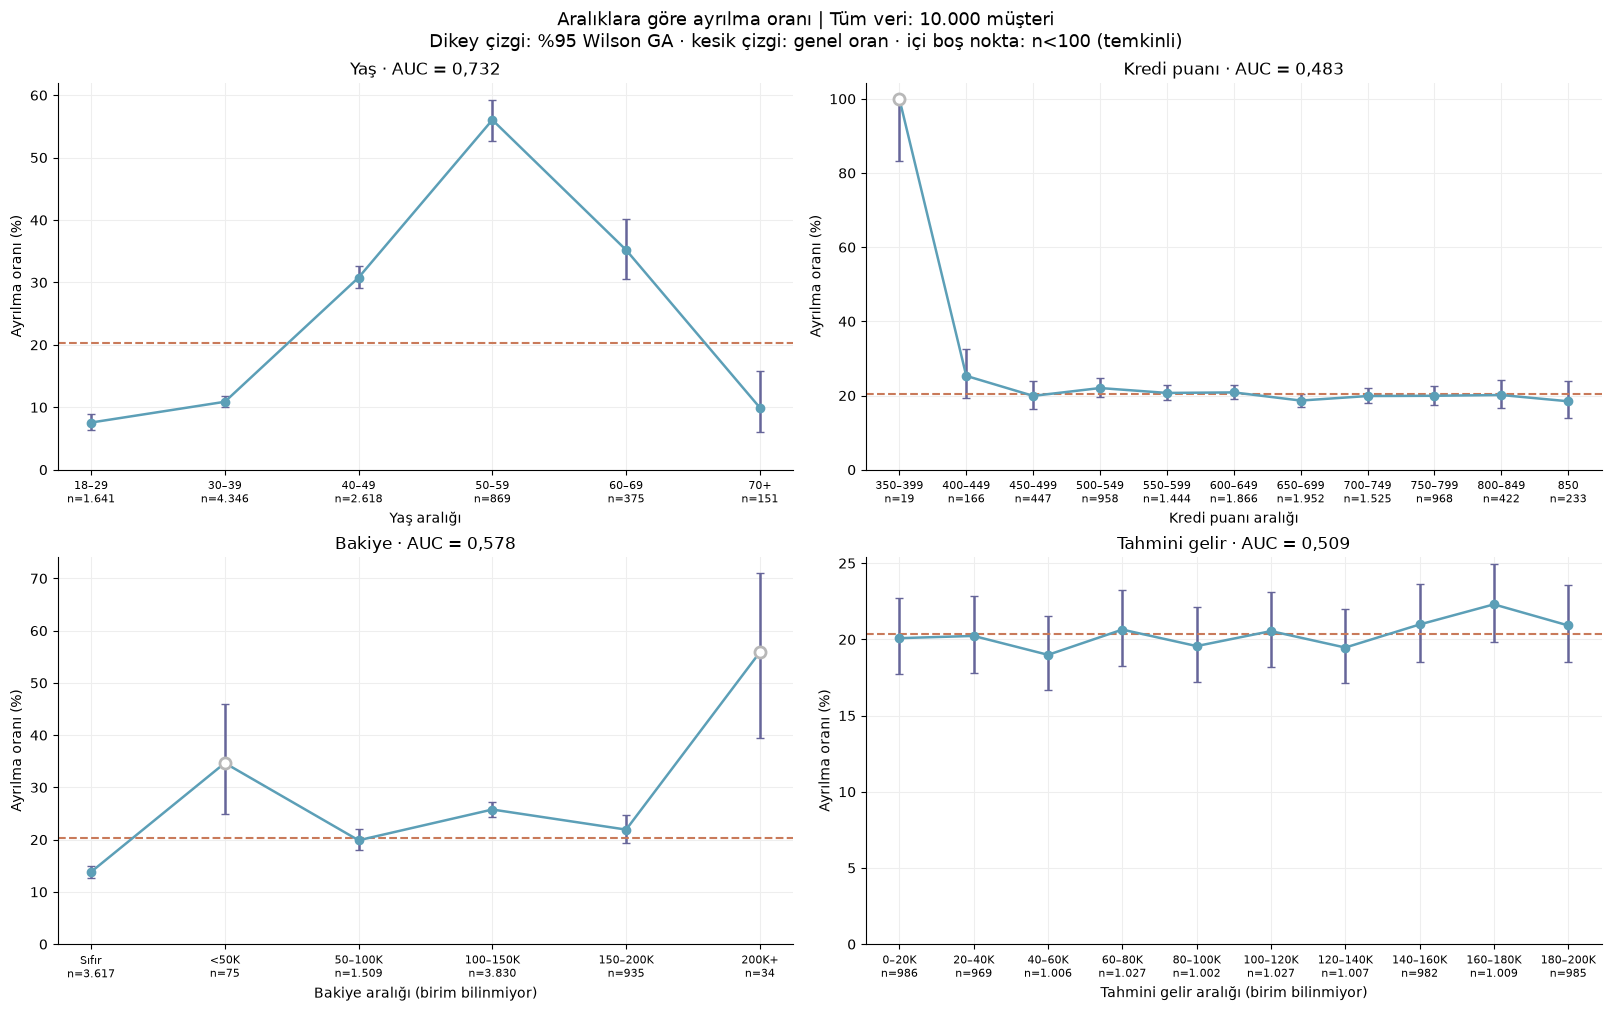

Müşteri sayısı  Ayrılan sayısı  Ayrılma oranı (%)  \
Değişken      Aralık                                                        
Yaş           18–29               1641             124               7.56   
              30–39               4346             473              10.88   
              40–49               2618             806              30.79   
              50–59                869             487              56.04   
              60–69                375             132              35.20   
              70+                  151              15               9.93   
Kredi puanı   350–399               19              19             100.00   
              400–449              166              42              25.30   
              450–499              447              89              19.91   
              500–549              958             211              22.03   
              550–599             1444             299              20.71   
              600–649             1866             389              20.85   
              650–699             1952             364              18.65   
              700–749             1525             303              19.87   
              750–799              968             193              19.94   
              800–849              422              85              20.14   
              850                  233              43              18.45   
Bakiye        Sıfır               3617             500              13.82   
              <50K                  75              26              34.67   
              50–100K             1509             300              19.88   
              100–150K            3830             987              25.77   
              150–200K             935             205              21.93   
              200K+                 34              19              55.88   
Tahmini gelir 0–20K                986             198              20.08   
              20–40K               969             196              20.23   
              40–60K              1006             191              18.99   
              60–80K              1027             212              20.64   
              80–100K             1002             196              19.56   
              100–120K            1027             211              20.55   
              120–140K            1007             196              19.46   
              140–160K             982             206              20.98   
              160–180K            1009             225              22.30   
              180–200K             985             206              20.91   

                        GA alt (%)  GA üst (%)  Lift  Temkinli (n<100)  
Değişken      Aralık                                                    
Yaş           18–29           6.37        8.94  0.37             False  
              30–39           9.99       11.84  0.53             False  
              40–49          29.05       32.58  1.51             False  
              50–59          52.72       59.31  2.75             False  
              60–69          30.54       40.16  1.73             False  
              70+             6.11       15.74  0.49             False  
Kredi puanı   350–399        83.18      100.00  4.91              True  
              400–449        19.30       32.42  1.24             False  
              450–499        16.47       23.86  0.98             False  
              500–549        19.52       24.76  1.08             False  
              550–599        18.70       22.87  1.02             False  
              600–649        19.06       22.75  1.02             False  
              650–699        16.98       20.44  0.92             False  
              700–749        17.94       21.95  0.98             False  
              750–799        17.54       22.57  0.98             False  
              800–849        16.59       24.23  0.99             False  
              

In [5]:
# 2b: dört sürekli alanda aralıklı ayrılma oranı eğrisi (aralıklar: eda.ARALIKLAR) ve AUC
surekli = eda.surekli_hedef(veri, cikti_klasoru)
display(surekli.round(2))

**Gözlem:** Yaşın ham AUC'si 0,732; ayrılma oranı 50–59'da %56,0'a çıkıp 70+'da %9,9'a düşüyor. Bakiye AUC 0,578; sıfır bakiyede %13,8, çoğu pozitif tutar aralığında %19,9–25,8. Kredi puanı AUC 0,483, gelir 0,509; bu tek değişkenli ölçüde sıralama ayrımı sınırlı.

**İş anlamı:** Yaş için yalnız doğrusal artış varsayımı yetersiz olabilir; sıfır bakiye ile tutarı ayırmak betimsel olarak yararlı. Düşük tek değişkenli AUC, o alanın bütün çok değişkenli kullanımının değersiz olduğunu kanıtlamaz.

**Sınır:** 70+ grubunda 151 müşteri ama yalnız 15 ayrılan var; sayı ve aralıkla okunmalı. 405 altındaki 21 müşterinin hepsinin ayrılması keşif sonrası bulunmuş küçük bir örüntüdür; özel kural yapılmaz. Aralıklar üretim sürecini veya gelecekteki riski doğrulamaz.

### 2c. Etki büyüklüğü sıralaması

V ile AUC aynı ölçekte değildir. Sıralama için AUC 2·|AUC − 0,5| ile 0–1 aralığına çevrilir (**Güç**). Bu kaba bir sıralamadır, kesin bir derecelendirme değildir.

**Önceden yazılmış kural:** Güç ≥ 0,10 olan değişkenler Bölüm 4'e (etkileşim ve karıştırıcılar) taşınır. Sürekli değişkenlerde ayrılan ve kalanların medyanı, AUC'nin somut karşılığı olarak verilir.

,Değişken,Ölçü,Değer,Güç,Test,p-değeri (referans),Medyan (kalan),Medyan (ayrılan),Bölüm 4'e taşınır
0,Yaş,AUC,0.732,0.464,Mann-Whitney U,"<0,001",36.00,45.00,True
1,Ürün sayısı,Cramér's V,0.388,0.388,Ki-kare,"<0,001",NaN,NaN,True
2,Ülke,Cramér's V,0.174,0.174,Ki-kare,"<0,001",NaN,NaN,True
3,Aktiflik,Cramér's V,0.156,0.156,Ki-kare,"<0,001",NaN,NaN,True
4,Bakiye,AUC,0.578,0.155,Mann-Whitney U,"<0,001",92072.68,109349.29,True
5,Bakiye durumu,Cramér's V,0.122,0.122,Ki-kare,"<0,001",NaN,NaN,True
6,Cinsiyet,Cramér's V,0.107,0.107,Ki-kare,"<0,001",NaN,NaN,True
7,Banka ile ilişki süresi,Cramér's V,0.037,0.037,Ki-kare,"0,178",NaN,NaN,False
8,Kredi puanı,AUC,0.483,0.033,Mann-Whitney U,"0,020",653.00,646.00,False
9,Tahmini gelir,AUC,0.509,0.017,Mann-Whitney U,"0,227",99645.04,102460.84,False


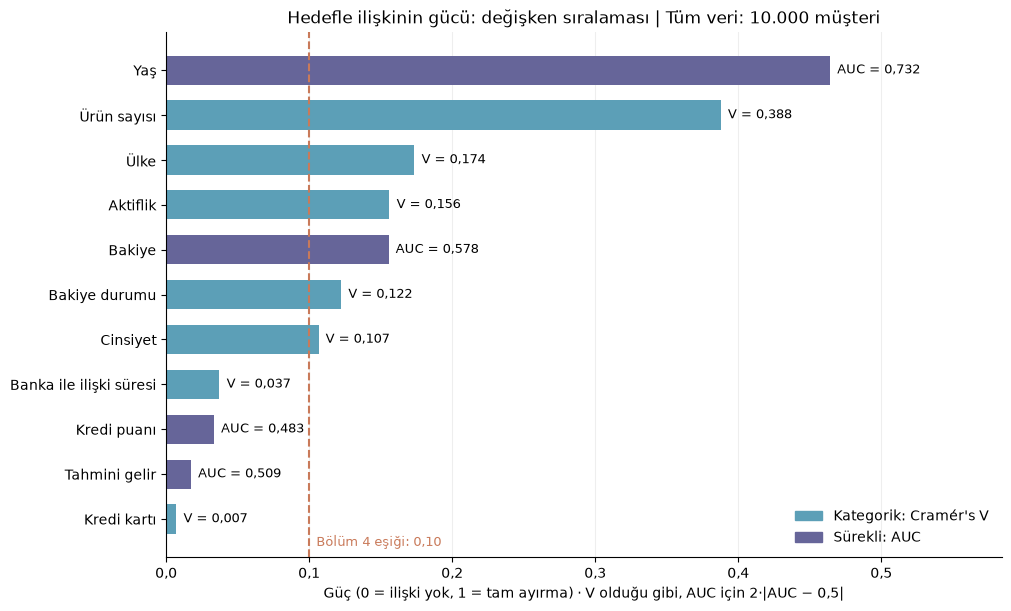

In [6]:
# 2c: etki büyüklüğü sıralaması; p-değeri yalnızca referans, seçim Güç ≥ 0,10 kuralıyla
etki = eda.etki_buyuklugu(veri)
display(etki.assign(**{"p-değeri (referans)": etki["p-değeri (referans)"].map(eda.p_metin)}).round(3))
eda.etki_grafigi(etki, cikti_klasoru);

**Gözlem:** Bu betimsel sıralamada yaşın dönüştürülmüş gücü 0,464, ürün sayısının V'si 0,388; ülke 0,174, aktiflik 0,156, bakiye 0,155, bakiye durumu 0,122 ve cinsiyet 0,107. Tenure, kredi puanı, gelir ve kartta kullanılan ölçü <0,04.

**İş anlamı:** Sonraki incelemeye öncelik verir; zayıf görünen alanlar otomatik modelden çıkarılmaz. Kredi puanında küçük p-değeri, ilişkinin iş açısından büyük olduğunu göstermez.

**Sınır:** Cramér's V ile dönüştürülmüş AUC tam eşdeğer değildir; sıra kaba bir özettir. p-değeri farkın varlığını kesinleştirmez; etki büyüklüğü de iş değerini tek başına belirlemez. Ters U gibi ilişkiler ham AUC'de eksik özetlenebilir.

## 3. Yeterlilik

**Soru:** Grup oranlarının hangi sayılara ve ne genişlikte aralıklara dayandığını nasıl görünür kılarız?

**Yöntem:** 59 örtüşen grup için n, ayrılan, oran, Wilson aralığı ve lift raporlanır. Paneldeki tarihsel etiket sözlüğü korunur: aralık genel oranın üstündeyse “Yüksek risk”, altındaysa “Düşük risk”, genel oranı içeriyorsa “Fark yok”; gücü <0,10 olan değişkenler “Yorumlanmaz”. “Fark yok”, eşit oran kanıtı değil, kullanılan betimsel kuralda ayrışma işareti görülmemesidir.

“Güven” etiketi n < 100 için düşük, diğer gruplarda aralık genişliği ≤10 puan için yüksek, daha genişse ortadır. Bunlar sunum eşikleridir; doğrulanmış güvenilirlik veya sıralama garantisi değildir. Ayrılan sayısı azsa n büyük olsa da belirsizlik önemlidir.

**Sınır:** Genel oran aynı müşterileri içerir; bu kontrol bağımsız iki grup testi değildir. Tek başına Wilson aralığını bu genel oranla karşılaştırmak, gruplar arası fark testi yerine geçmez. Gruplar ve sınırlar veride keşfedildi; Bonferroni kontrolü bu seçim sürecinin bütün belirsizliğini kapsamaz. Etiketler nedensellik, gelecek performans veya teklif etkisi göstermez.

### 3a. Grupların etiketlenmesi

Önce etiketlerin dağılımı (59 grup), ardından ortalamadan güvenilir biçimde yüksek riskli gruplar.

In [7]:
# 3a: 59 gruba "Ortalamaya göre" ve "Güven" etiketi (kurallar: eda.ortalamaya_gore, eda.guven_etiketi)
guven = eda.guven_tablosu(veri, etki, cikti_klasoru)
display(pd.crosstab(guven["Ortalamaya göre"], guven["Güven"], margins=True, margins_name="Toplam"))

Güven,Düşük (n < 100),Orta,Yüksek,Toplam
Ortalamaya göre,,,,
Düşük risk,0,0,10,10
Fark yok,0,0,2,2
Yorumlanmaz (zayıf değişken),1,1,32,34
Yüksek risk,3,0,10,13
Toplam,4,1,54,59


,Değişken,Grup,Müşteri sayısı,Ayrılma oranı (%),GA alt (%),GA üst (%),GA genişliği (puan),Lift,Güven
12,Ürün sayısı,4 ürün,60,100.00,93.98,100.00,6.02,4.91,Düşük (n < 100)
11,Ürün sayısı,3 ürün,266,82.71,77.70,86.78,9.07,4.06,Yüksek
29,Yaş,50–59,869,56.04,52.72,59.31,6.59,2.75,Yüksek
48,Bakiye,200K+,34,55.88,39.45,71.12,31.66,2.74,Düşük (n < 100)
30,Yaş,60–69,375,35.20,30.54,40.16,9.62,1.73,Yüksek
44,Bakiye,<50K,75,34.67,24.88,45.95,21.06,1.70,Düşük (n < 100)
1,Ülke,Almanya,2509,32.44,30.64,34.30,3.66,1.59,Yüksek
28,Yaş,40–49,2618,30.79,29.05,32.58,3.53,1.51,Yüksek
9,Ürün sayısı,1 ürün,5084,27.71,26.50,28.96,2.46,1.36,Yüksek
7,Aktiflik,Aktif değil,4849,26.85,25.62,28.12,2.49,1.32,Yüksek


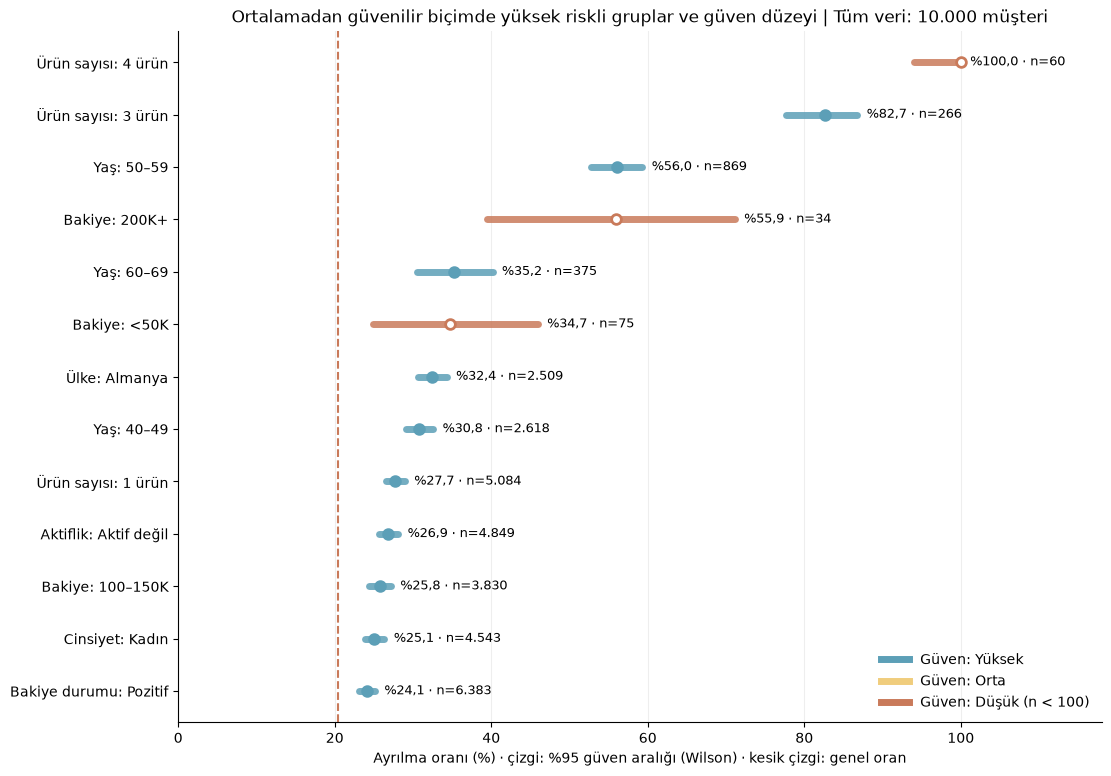

In [8]:
# Ortalamadan güvenilir biçimde yüksek riskli gruplar, lift sırasıyla
sutunlar = ["Değişken", "Grup", "Müşteri sayısı", "Ayrılma oranı (%)", "GA alt (%)", "GA üst (%)",
            "GA genişliği (puan)", "Lift", "Güven"]
display(guven.loc[guven["Ortalamaya göre"].eq(eda.ORT_YUKSEK), sutunlar].sort_values("Lift", ascending=False).round(2))
eda.guven_grafigi(guven, genel_oran, len(veri), cikti_klasoru);

**Gözlem:** Tarihsel etiket kuralı 59 grubun 13'ünü genel oranın üstünde işaretliyor. 3 ürün, 50–59 yaş, 60–69 yaş ve Almanya yüksek gözlenen oranlarla öne çıkıyor. 1 ürün, aktif olmayanlar, kadınlar ve pozitif bakiye daha geniş müşteri grupları; ayrılan payları yüksek olsa da müşteri payları da yüksek.

**İş anlamı:** Kapasite kararında yalnız “çok ayrılan içeriyor” yeterli değildir; müşteri payı ve lift de gerekir. 4 üründe 60/60 gibi küçük gruplar daha geniş veriyle incelenmeli.

**Sınır:** “Yüksek güven” yalnız n/aralık genişliği etiketidir; oran kesin bilinmez. “Düşük risk” bu verideki göreli orandır. Gruplar örtüştüğü için paylar toplanamaz; genel oranla karşılaştırma bağımsız fark testi değildir.

### 3b. Duyarlılık analizi: sonuç eşik seçimine bağlı mı?

**Soru:** Eşikleri (100 müşteri, 10 puan, 0,10 güç) farklı seçseydik yüksek riskli gruplar değişir miydi?

**Yöntem ve gerekçe:** Eşikler yaygın kabul gören değerlere ve iş ihtiyacına dayanıyor, ama kesin değiller; başka bir analist farklı değerler seçebilirdi. Bu yüzden her eşik daha gevşek ve daha sıkı değerlerle yeniden uygulanır: küçük grup eşiği 50 ve 200, aralık eşiği 8 ve 15 puan, güç eşiği 0,05 ve 0,15; ayrıca hepsi birlikte gevşek ve hepsi birlikte sıkı. Sonuç değişmiyorsa bulgular eşik seçimine dayanmıyor demektir.

Ek olarak 59 karşılaştırma için formal bir çoklu karşılaştırma kontrolü yapılır: **Bonferroni düzeltmesi**, her karşılaştırmanın güven düzeyini %95'ten 1 − 0,05/59 ≈ %99,9'a çıkarır ve aralıkları genişletir. Seçim kuralı olarak değil, sağlamlık kontrolü olarak kullanılır; seçim kuralı olsaydı gerçek ama orta büyüklükteki farkları da gölgelerdi.

In [9]:
# 3b: her senaryoda yüksek riskli grup sayısı ve temel senaryodan farkı
display(eda.duyarlilik_analizi(veri, etki, cikti_klasoru))

,Senaryo,Küçük grup eşiği (n),GA eşiği (puan),Güç eşiği,Yüksek riskli grup,Yüksek güven,Orta güven,Düşük güven (n küçük),Temel senaryodan farkı
0,Temel,100,10.0,0.10,13,10,0,3,Fark yok
1,Küçük grup eşiği 50,50,10.0,0.10,13,11,1,1,Yüksek güvene geçen: Ürün sayısı: 4 ürün
2,Küçük grup eşiği 200,200,10.0,0.10,13,10,0,3,Fark yok
3,GA eşiği 8 puan,100,8.0,0.10,13,8,2,3,"Yüksek güvenden düşen: Yaş: 60–69, Ürün sayısı..."
4,GA eşiği 15 puan,100,15.0,0.10,13,10,0,3,Fark yok
5,"Güç eşiği 0,05",100,10.0,0.05,13,10,0,3,Fark yok
6,"Güç eşiği 0,15",100,10.0,0.15,11,8,0,3,"Yüksek riskten çıkan: Bakiye durumu: Pozitif, ..."
7,Hepsi gevşek,50,15.0,0.05,13,11,1,1,Yüksek güvene geçen: Ürün sayısı: 4 ürün
8,Hepsi sıkı,200,8.0,0.15,11,6,2,3,"Yüksek riskten çıkan: Bakiye durumu: Pozitif, ..."


In [10]:
# Bonferroni kontrolü: yüksek riskli gruplar 59 karşılaştırma düzeltmesinden sonra da yüksek riskli mi?
bonf = eda.bonferroni_kontrolu(guven, genel_oran, cikti_klasoru)
print(f"Karşılaştırma sayısı: {bonf.attrs['k']} | z = {eda.tr_sayi(bonf.attrs['z'], 2)} (yerine 1,96)")
display(bonf.round(1))

Karşılaştırma sayısı: 59 | z = 3,34 (yerine 1,96)


,Değişken,Grup,Müşteri sayısı,Ayrılma oranı (%),GA alt (%),"GA alt, Bonferroni (%)",Güven,Bonferroni sonrası yüksek risk
12,Ürün sayısı,4 ürün,60,100.0,94.0,84.3,Düşük (n < 100),Evet
11,Ürün sayısı,3 ürün,266,82.7,77.7,73.7,Yüksek,Evet
29,Yaş,50–59,869,56.0,52.7,50.4,Yüksek,Evet
48,Bakiye,200K+,34,55.9,39.5,29.7,Düşük (n < 100),Evet
30,Yaş,60–69,375,35.2,30.5,27.5,Yüksek,Evet
44,Bakiye,<50K,75,34.7,24.9,19.4,Düşük (n < 100),Hayır
1,Ülke,Almanya,2509,32.4,30.6,29.4,Yüksek,Evet
28,Yaş,40–49,2618,30.8,29.0,27.9,Yüksek,Evet
9,Ürün sayısı,1 ürün,5084,27.7,26.5,25.7,Yüksek,Evet
7,Aktiflik,Aktif değil,4849,26.9,25.6,24.8,Yüksek,Evet


**Gözlem:** İncelenen dokuz eşik senaryosunda 50–59/40–49 yaş, Almanya, 1 ürün, aktif olmayanlar ve 100–150K bakiye etiketleri büyük ölçüde korunuyor. 4 ürün grubunun güven etiketi n eşiğine; kadınlar ve pozitif bakiyenin yorumlanması güç eşiğine duyarlı. Bonferroni aralık kontrolünde yüksek işaretlenen 13 grubun 12'si korunuyor.

**İş anlamı:** Sunum eşikleri değiştiğinde hangi bulguların yer değiştirdiğini gösterir; eşik sınırındaki yorumlar özellikle temkinli sunulur.

**Sınır:** Bu, yalnız denenmiş eşiklere duyarlılıktır. Veride keşfedilmiş grup/sınır seçiminin bütün etkisini veya başka müşterilerde tekrarlanabilirliği doğrulamaz.

## 4. Etkileşim ve karıştırıcılar

**Soru:** Değişkenlere birlikte bakınca Bölüm 2–3'teki tablo değişiyor mu?

**Yöntem ve gerekçe:** İki ayrı tuzak aranır:

| Kavram | Soru | Neden önemli |
|---|---|---|
| **Karıştırma** | A'nın etkisi gerçekte B'den mi geliyor? | Varsa segment tablosunda aynı risk iki kez sayılır |
| **Etkileşim** | A'nın etkisi B'nin seviyesine göre değişiyor mu? | Varsa iki değişken ayrı ayrı değil, birlikte segment yapılmalı |

Kapsam önceden yazılmış kurala göre Bölüm 2c'de gücü ≥ 0,10 olan altı değişken: yaş, ürün sayısı, ülke, aktiflik, bakiye durumu, cinsiyet. Çapraz tablolarda hücreler küçülmesin diye yaş beş gruba (18–39, 40–49, 50–59, 60–69, 70+), ürün sayısı üç gruba (1, 2, 3+) indirilir. Etkiler her değişkenin düşük riskli ve kalabalık referans grubuna göre yüzde puan olarak ölçülür (referanslar: 18–39 yaş, 2 ürün, Fransa, aktif, sıfır bakiye, erkek).

Kurallar ve dayanakları:

- **4a. İlişki:** Karıştırma ancak iki değişken birbiriyle ilişkiliyse mümkündür. Değişkenler arası Cramér's V ≥ 0,10 olan çiftler karıştırma adayıdır (Bölüm 2c ile aynı "küçük etki" sınırı).
- **4b. Karıştırma:** A'nın etkisi önce ham, sonra B'nin katmanları içinde Mantel–Haenszel ağırlıklı risk farkı olarak hesaplanır (güven aralığı: Sato varyansı). Ayarlanmış fark hamdan en az %10 farklıysa karıştırma vardır. Bu, epidemiyolojide yaygın kullanılan *change-in-estimate* ölçütüdür (Greenland 1989; Mickey ve Greenland 1989). Ham fark 0'dan ayırt edilemiyorsa yüzde değişim hesaplanmaz.
- **4c. Etkileşim:** Her iki seviye çifti için fark farkı hesaplanır: [p(a, b) − p(ref, b)] − [p(a, ref) − p(ref, ref)]. En az 10 puan (pratik önem eşiği), %95 güven aralığı 0'ı içermiyor ve dört hücrenin hepsi n ≥ 100 ise *etkileşim adayı*; hücrelerden biri boşsa *değerlendirilemez*. Sağlamlık kontrolü olarak Bonferroni düzeltmesi uygulanır.
- **4d. Çok değişkenli kontrol:** sığ karar ağacı ve etkileşimli lojistik regresyon (olabilirlik oranı testi; ayrıntı 4d'de).

**Sınır:** Bulgular ilişkiseldir; karıştırma ve etkileşim burada istatistiksel anlamda kullanılır, nedensel bir model kurulmamıştır. Etkileşim yüzde puan ölçeğinde ölçülür; odds ratio ölçeğinde sonuç farklı olabilir.

### 4a. Hangi değişkenler birbiriyle ilişkili?

15 değişken çifti arasında Cramér's V. Kalın değerler karıştırma adayıdır; 4b yalnızca bu çiftlere bakar.

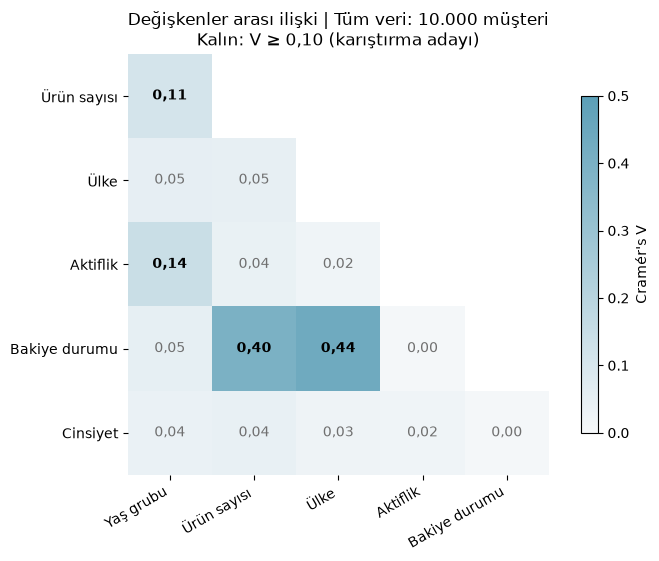

,Değişken A,Değişken B,Cramér's V,En küçük hücre (n),Karıştırma adayı
0,Ülke,Bakiye durumu,0.436,0,Evet
1,Ürün sayısı,Bakiye durumu,0.397,112,Evet
2,Yaş grubu,Aktiflik,0.143,17,Evet
3,Yaş grubu,Ürün sayısı,0.111,3,Evet
4,Yaş grubu,Ülke,0.053,34,Hayır
5,Yaş grubu,Bakiye durumu,0.050,61,Hayır
6,Ürün sayısı,Ülke,0.047,73,Hayır
7,Ürün sayısı,Cinsiyet,0.044,139,Hayır
8,Ürün sayısı,Aktiflik,0.041,142,Hayır
9,Yaş grubu,Cinsiyet,0.039,75,Hayır


In [11]:
# 4a: Bölüm 4 için sadeleştirilmiş gruplar ve değişkenler arası ilişki (eda.bolum4_verisi, eda.REFERANS)
d4 = eda.bolum4_verisi(veri)
iliski = eda.iliski_matrisi(d4, cikti_klasoru)
display(iliski.round(3))

**Gözlem:** İncelenen 15 çiftte bakiye durumu–ülke V=0,44, bakiye durumu–ürün V=0,40; yaş–aktiflik 0,14, yaş–ürün 0,11. Diğer çiftlerde bu özet ölçü daha küçük.

**İş anlamı:** Ülke ve ürün katmanlarında bakiye ilişkisini ayrıca incelemek için gerekçe sağlar.

**Sınır:** Düşük ikili V bağımsızlık kanıtı değildir; yalnız bu ölçüyle karıştırmanın mümkün olmadığı söylenemez. Ölçülmeyen değişkenler ve çok değişkenli örüntüler de olabilir.

### 4b. Katmanlı karşılaştırma: gözlenen fark ne kadar değişiyor?

İncelenen çiftler iki yönde katmanlanır. Tablodaki tarihsel “etkinin kalan payı” adı, ayarlanmış ilişki farkının ham ilişki farkına oranıdır. %50 görülmesi nedenin yarısının diğer değişkenden geldiğini veya %100 görülmesi bağımsızlığı kanıtlamaz. Ortak gözlem bulunmayan katmanlarda karşılaştırma yapılamaz; etkileşim varsa tek ayarlanmış değer farklı yönleri örtebilir.

In [12]:
# 4b: karıştırma (Mantel–Haenszel ağırlıklı risk farkı; change-in-estimate %10)
etkilesim = eda.etkilesim_tablosu(d4, cikti_klasoru)  # 4c'de ayrıntılı; burada etkileşim uyarısı için
karistirma = eda.karistirma_tablosu(d4, iliski, etkilesim, cikti_klasoru)
display(karistirma[["Etkisi ölçülen", "Kontrol edilen", "Ham fark (puan)", "Ayarlanmış fark (puan)",
                    "Ayarlanmış GA alt", "Ayarlanmış GA üst", "Etkinin kalan payı (%)", "Karıştırma",
                    "Bu çiftte etkileşim adayı", "Katkı vermeyen katman"]].round(1))

,Etkisi ölçülen,Kontrol edilen,Ham fark (puan),Ayarlanmış fark (puan),Ayarlanmış GA alt,Ayarlanmış GA üst,Etkinin kalan payı (%),Karıştırma,Bu çiftte etkileşim adayı,Katkı vermeyen katman
0,Ülke: Almanya (ref. Fransa),Bakiye durumu,16.3,14.2,11.9,16.6,87.3,Var,Değerlendirilemez (boş hücre),Sıfır
1,Ülke: İspanya (ref. Fransa),Bakiye durumu,0.5,0.5,-1.3,2.3,NaN,Değerlendirilemez (ham fark ≈ 0),Hayır,—
2,Bakiye durumu: Pozitif (ref. Sıfır),Ülke,10.3,4.8,3.2,6.5,47.2,Var,Değerlendirilemez (boş hücre),Almanya
3,Ürün sayısı: 1 ürün (ref. 2 ürün),Bakiye durumu,20.1,19.6,18.0,21.3,97.5,Yok,Evet,—
4,Ürün sayısı: 3+ ürün (ref. 2 ürün),Bakiye durumu,78.3,75.9,72.0,79.8,96.9,Yok,Evet,—
5,Bakiye durumu: Pozitif (ref. Sıfır),Ürün sayısı,10.3,2.3,0.6,3.9,22.1,Var,Evet,—
6,Yaş grubu: 40–49 (ref. 18–39),Aktiflik,20.8,20.5,18.6,22.4,98.5,Yok,Evet,—
7,Yaş grubu: 50–59 (ref. 18–39),Aktiflik,46.1,46.7,43.4,50.1,101.5,Yok,Evet,—
8,Yaş grubu: 60–69 (ref. 18–39),Aktiflik,25.2,27.3,22.5,32.1,108.1,Yok,Küçük hücre (n < 100),—
9,Yaş grubu: 70+ (ref. 18–39),Aktiflik,-0.0,2.1,-2.7,6.9,NaN,Değerlendirilemez (ham fark ≈ 0),Küçük hücre (n < 100),—


In [13]:
# Bakiye aralıkları × ülke: Bölüm 3'te yüksek riskli çıkan 100–150K aralığı
display(eda.bakiye_ulke_tablosu(veri, cikti_klasoru).round(1))

Ayrılma oranı (%)                 Müşteri sayısı                  \
Ülke                Fransa Almanya İspanya         Fransa Almanya İspanya   
Bakiye                                                                      
Sıfır                 13.9     NaN    13.6           2418       0    1199   
<50K                  48.8     0.0    40.0             41      19      15   
50–100K               17.0    20.6    24.3            647     524     338   
100–150K              16.1    39.1    14.7           1476    1652     702   
150–200K              22.8    19.5    23.7            416     308     211   
200K+                 62.5     0.0    75.0             16       6      12   

         Ülke payı (%)                  
Ülke            Fransa Almanya İspanya  
Bakiye                                  
Sıfır             66.9     0.0    33.1  
<50K              54.7    25.3    20.0  
50–100K           42.9    34.7    22.4  
100–150K          38.5    43.1    18.3  
150–200K          44.5    32.9    22.6  
200K+             47.1    17.6    35.3

**Gözlem:** Pozitif bakiye ile ayrılmanın ham farkı +10,3 puan; ülke katmanlarında özet +4,8 puan. Ürün sayısına göre farkın yönü değişiyor: 1 üründe −11,7, 2 üründe +9,9, 3+ üründe +27,4 puan. Almanya farkı ham +16,3, pozitif bakiye ortak desteğinde +14,2 puan. 100–150K bakiye grubunun ülke bileşimi de farklı.

**İş anlamı:** Bakiyeyi tek, sabit yönlü bir sinyal gibi yorumlamak yetersiz; ülke ve ürün bileşimiyle birlikte incelenmeli.

**Sınır:** Katmanlı ayarlama nedenleri paylaştırmaz. Almanya'da sıfır bakiye gözlemi olmadığı için o katmanda Almanya karşılaştırması yoktur. Dar aralık ölçülmeyen karıştırıcıları, keşif seçimini veya teklif etkisini kapsamaz; karşıt katman farklarının ortalaması tek başına öneriye dönüştürülmez.

### 4c. Etkileşim: bir değişkenin etkisi diğerinin seviyesine göre değişiyor mu?

15 çiftin bütün seviye kombinasyonlarında fark farkı (yüzde puan). Önce sonuç dağılımı ve adaylar, ardından adayı olan çiftlerin hücre oranları. Isı haritalarında renk ayrılma oranını, yazı oranı ve müşteri sayısını gösterir; gri italik hücreler n < 100'dür.

In [14]:
# 4c: etkileşim adayları (|fark farkı| ≥ 10 puan, GA 0'ı içermiyor, dört hücre n ≥ 100) ve Bonferroni kontrolü
print(f"Karşılaştırma sayısı: {etkilesim.attrs['karsilastirma_sayisi']} "
      f"(değerlendirilebilen: {etkilesim.attrs['degerlendirilen']}) | "
      f"Bonferroni z = {eda.tr_sayi(etkilesim.attrs['z_bonferroni'], 2)}")
display(etkilesim["Sonuç"].value_counts().rename("Karşılaştırma"))
display(etkilesim[etkilesim["Sonuç"].ne("Yok")].round(1))

Karşılaştırma sayısı: 47 (değerlendirilebilen: 46) | Bonferroni z = 3,27


Sonuç
Yok                              33
Etkileşim adayı                  11
Küçük hücre (n < 100)             2
Değerlendirilemez (boş hücre)     1
Name: Karşılaştırma, dtype: int64

,Değişken A,Seviye A,Değişken B,Seviye B,"A'nın etkisi, B seviyesinde (puan)","A'nın etkisi, B referansında (puan)",Fark farkı (puan),GA alt,GA üst,En küçük hücre (n),Sonuç,Bonferroni sonrası
0,Yaş grubu,60–69,Aktiflik,Aktif değil,78.9,9.0,69.9,62.6,77.2,94,Küçük hücre (n < 100),Korunuyor
1,Yaş grubu,70+,Aktiflik,Aktif değil,40.3,-2.9,43.3,19.2,67.3,17,Küçük hücre (n < 100),Korunuyor
2,Yaş grubu,50–59,Aktiflik,Aktif değil,68.6,29.7,38.9,32.9,44.9,373,Etkileşim adayı,Korunuyor
3,Yaş grubu,50–59,Ürün sayısı,1 ürün,50.0,24.7,25.3,18.4,32.3,263,Etkileşim adayı,Korunuyor
4,Ürün sayısı,1 ürün,Bakiye durumu,Pozitif,12.5,34.0,-21.6,-25.4,-17.8,905,Etkileşim adayı,Korunuyor
5,Yaş grubu,40–49,Ürün sayısı,1 ürün,26.0,7.9,18.1,14.6,21.6,1086,Etkileşim adayı,Korunuyor
6,Ürün sayısı,3+ ürün,Bakiye durumu,Pozitif,82.2,64.5,17.6,8.4,26.9,112,Etkileşim adayı,Korunuyor
7,Yaş grubu,60–69,Ürün sayısı,1 ürün,28.9,12.9,15.9,6.8,25.1,143,Etkileşim adayı,Korunuyor
8,Yaş grubu,60–69,Bakiye durumu,Pozitif,29.9,15.9,14.1,4.5,23.6,130,Etkileşim adayı,Korunmuyor
9,Ürün sayısı,1 ürün,Ülke,Almanya,30.7,16.7,14.0,10.2,17.8,1040,Etkileşim adayı,Korunuyor


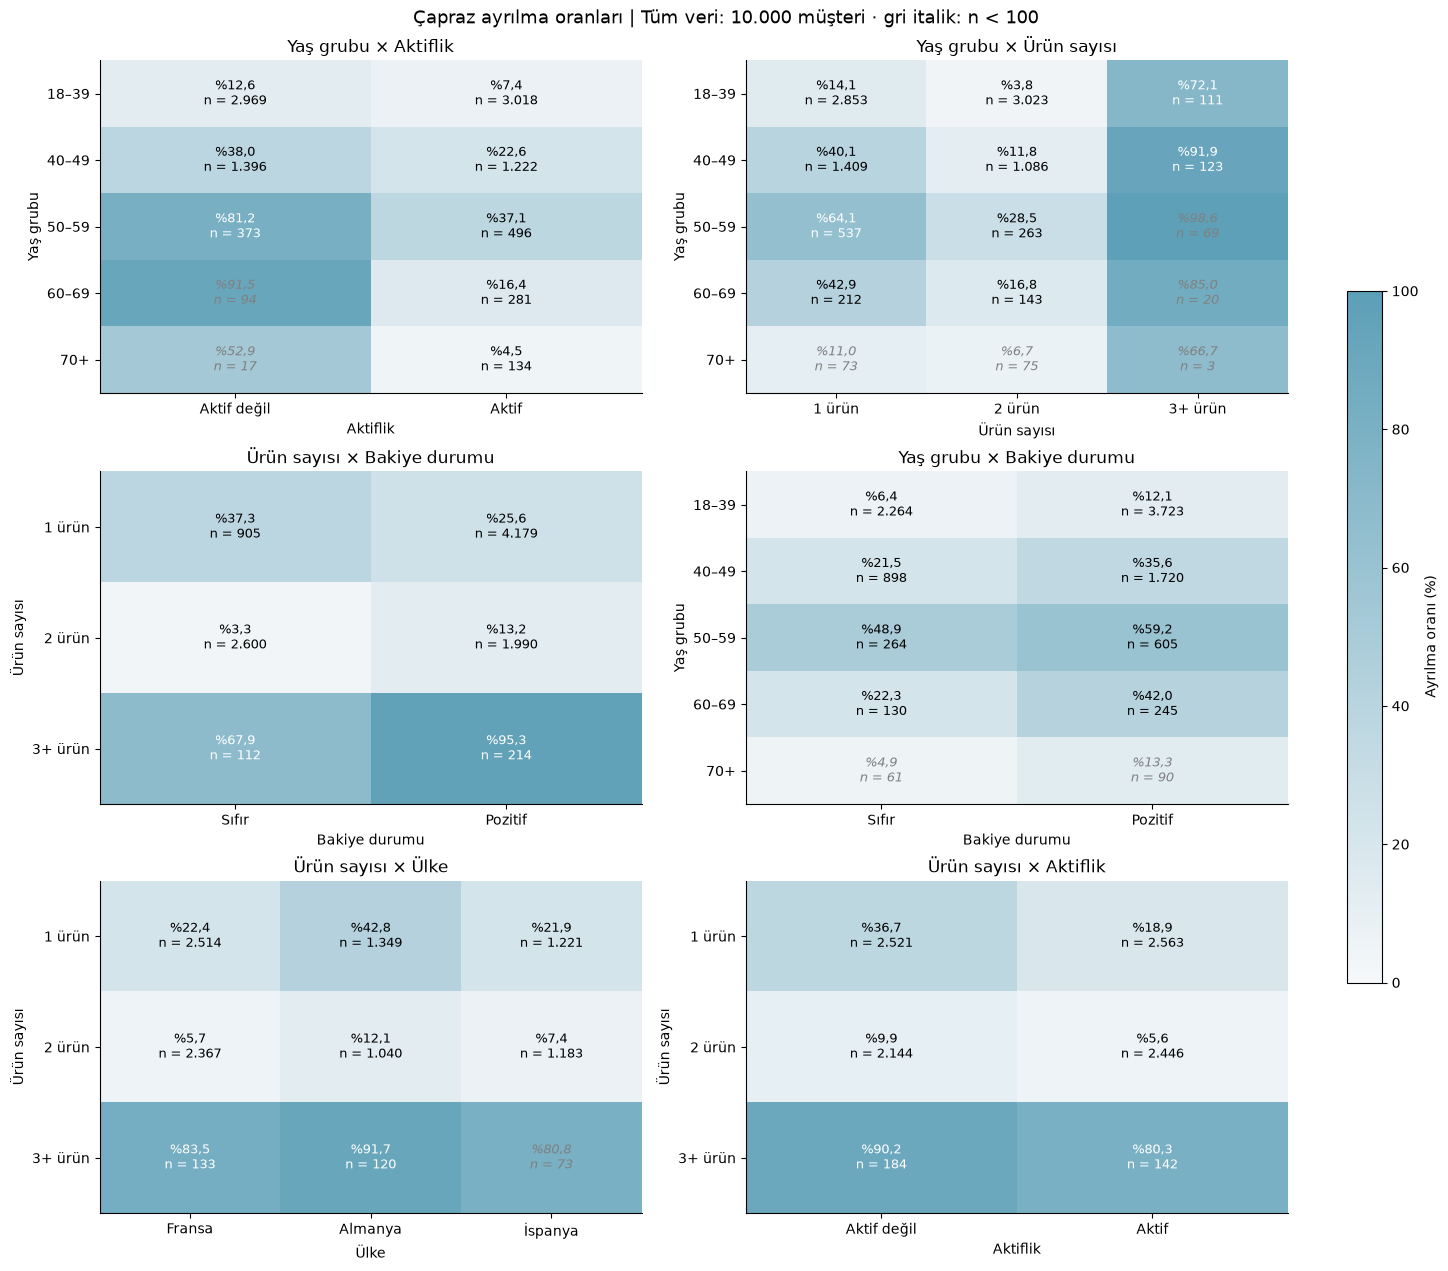

In [15]:
# Etkileşim adayı olan çiftlerde hücre bazında ayrılma oranları
adaylar = etkilesim[etkilesim["Sonuç"].eq("Etkileşim adayı")]
aday_ciftler = list(dict.fromkeys(zip(adaylar["Değişken A"], adaylar["Değişken B"])))
eda.capraz_isi_haritasi(d4, aday_ciftler, cikti_klasoru);

**Gözlem:** Aktif olmayan/olan farkı yaş gruplarına göre değişiyor: 18–39'da +5,2; 40–49'da +15,4; 50–59'da +44,1 puan. 50–59 yaşta aktif olmayanlarda %81,2 (n=373), aktiflerde %37,1. Ürün–bakiye farkının yönü de katmanlar arasında değişiyor. Cinsiyet için kullanılan aday ölçütünü geçen etkileşim bulunmaması etkileşimsizliği kanıtlamaz.

**İş anlamı:** Tek değişkenli özetler bu farklılıkları örtebilir; okunabilir kombinasyonlar betimsel incelemeye değer.

**Sınır:** İkili tablolar diğer alanları aynı anda kontrol etmez. Etkileşim yüzde puan ölçeğindedir; odds ölçeğinde aynı biçimde görünmeyebilir. Küçük hücreler, çoklu inceleme ve sonradan aday seçimi sonucu etkiler. Aktifliğin ayrılmadan önce ölçüldüğü bilinmiyor.

### 4d. Çok değişkenli betimsel kontrol: karar ağacı ve lojistik regresyon

Sığ CART ve lojistik regresyon aynı veri üzerinde iki farklı model varsayımıyla ilişkiyi özetler; birbirinden bağımsız doğrulama değildir. Ağaç en fazla 3 seviye / yaprakta en az 100 kayıtla okunabilir gruplar arar. Lojistik modeller ana etkiler ve aday/bütün ikili etkileşimleri odds ölçeğinde karşılaştırır; LR testleri ve çoklu karşılaştırma düzeltmesi keşif amaçlıdır.

**Sınır:** Her iki model tüm veride kurulmuştur; yaprak oranları tahmin performansı değildir. Aynı veride aday keşfedip sınamak seçim belirsizliği yaratır. Bu fikirlerin ML'ye taşınması tüm-veri EDA'sı sınırıyla açıklanır; yalnız katsayıların eğitimde öğrenilmesi geçmiş keşfi bağımsız hâle getirmez.

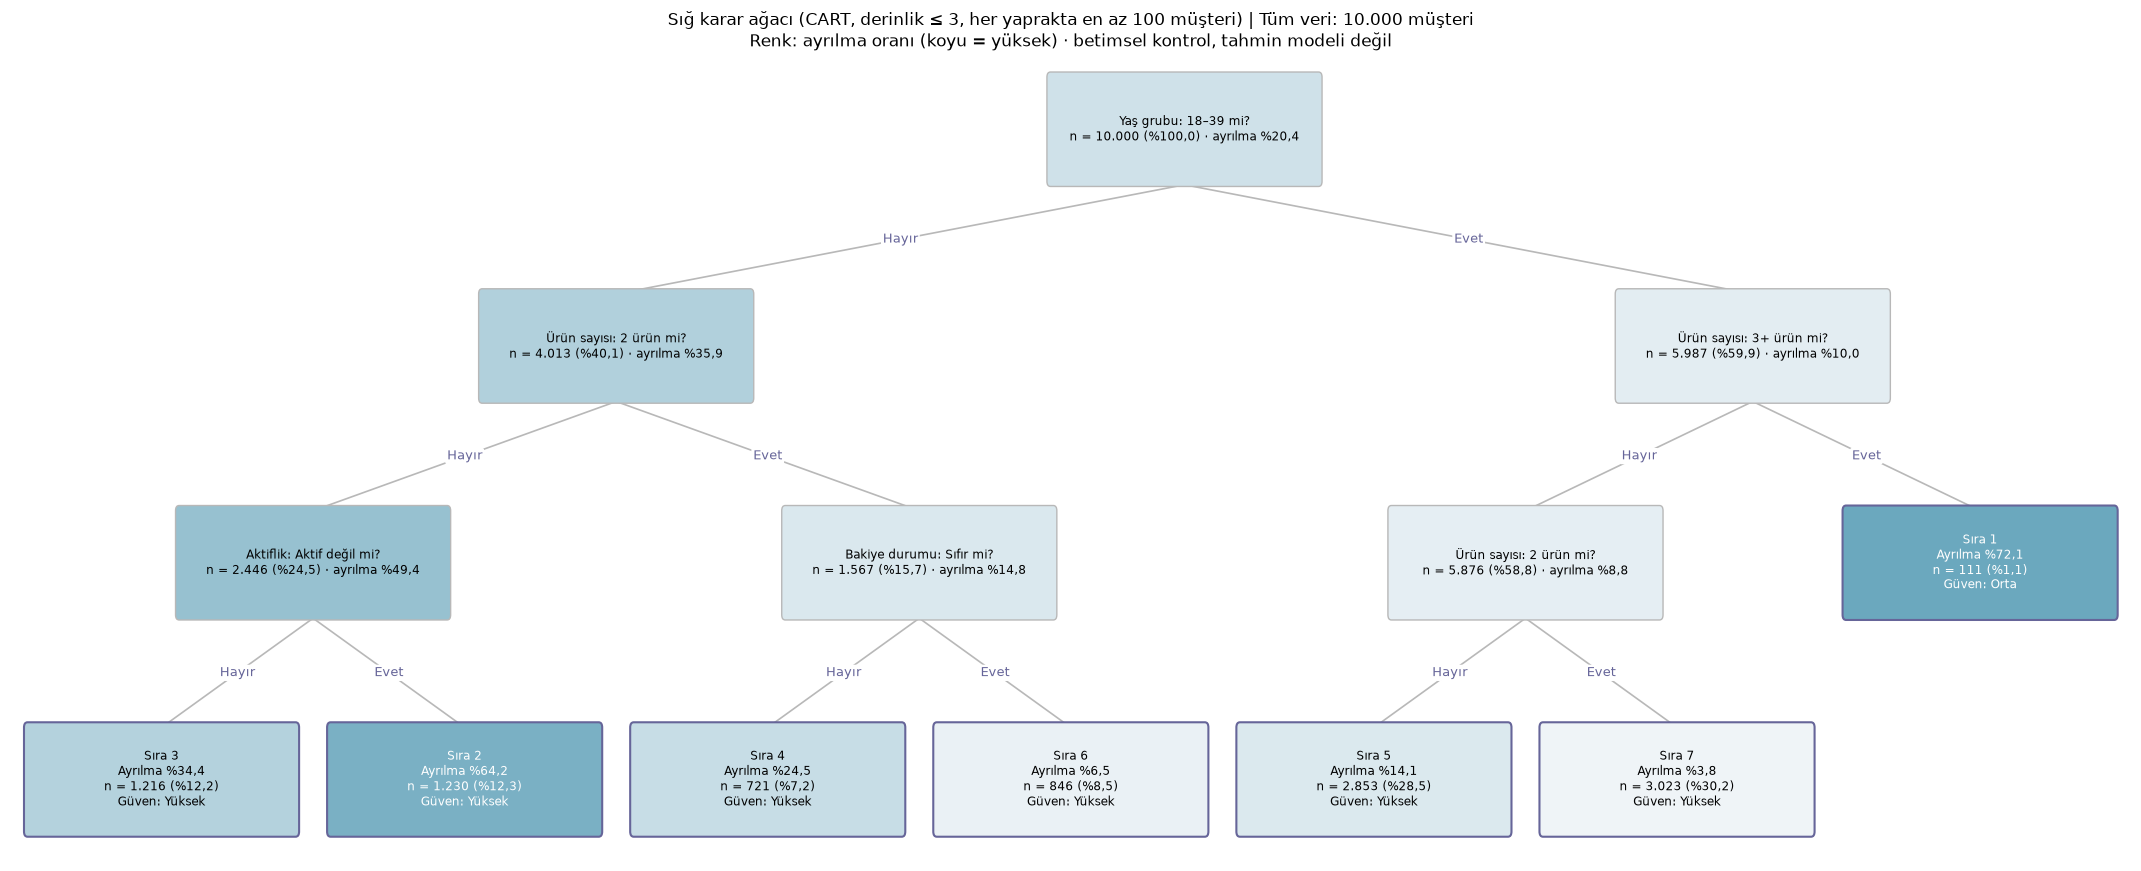

,Sıra,Kural,Müşteri sayısı,Ayrılan sayısı,Ayrılma oranı (%),GA alt (%),GA üst (%),Lift,Müşterilerin payı (%),Ayrılanların payı (%),Ortalamaya göre,Güven
0,1,Yaş grubu = 18–39 ve Ürün sayısı = 3+ ürün,111,80,72.1,63.1,79.6,3.5,1.1,3.9,Yüksek risk,Orta
1,2,Yaş grubu ≠ 18–39 ve Ürün sayısı ≠ 2 ürün ve A...,1230,790,64.2,61.5,66.9,3.2,12.3,38.8,Yüksek risk,Yüksek
2,3,Yaş grubu ≠ 18–39 ve Ürün sayısı ≠ 2 ürün ve A...,1216,418,34.4,31.8,37.1,1.7,12.2,20.5,Yüksek risk,Yüksek
3,4,Yaş grubu ≠ 18–39 ve Ürün sayısı = 2 ürün ve B...,721,177,24.5,21.5,27.8,1.2,7.2,8.7,Yüksek risk,Yüksek
4,5,Yaş grubu = 18–39 ve Ürün sayısı = 1 ürün,2853,401,14.1,12.8,15.4,0.7,28.5,19.7,Düşük risk,Yüksek
5,6,Yaş grubu ≠ 18–39 ve Ürün sayısı = 2 ürün ve B...,846,55,6.5,5.0,8.4,0.3,8.5,2.7,Düşük risk,Yüksek
6,7,Yaş grubu = 18–39 ve Ürün sayısı = 2 ürün,3023,116,3.8,3.2,4.6,0.2,30.2,5.7,Düşük risk,Yüksek


In [16]:
# 4d-1: sığ karar ağacı (derinlik ≤ 3, yaprakta en az 100 müşteri); yapraklar riske göre sıralı
yapraklar, agac = eda.karar_agaci(d4, cikti_klasoru)
display(yapraklar.drop(columns="Yaprak").round(1))

In [17]:
# 4d-2: lojistik regresyon; 4c adayları tek tek (Bonferroni), model karşılaştırması ve kaçırılan etkileşim kontrolü
tekli, modeller, kacirilan = eda.lojistik_etkilesim_testi(d4, etkilesim, cikti_klasoru)
print(f"Aday testi Bonferroni eşiği: p < {tekli.attrs['bonferroni_esigi']:.4f} | "
      f"Çift testi eşiği: p < {kacirilan.attrs['bonferroni_esigi']:.4f}")
display(tekli.assign(**{"p-değeri": tekli["p-değeri"].map(eda.p_metin)}).round(2))
display(modeller.assign(**{"p-değeri": modeller["p-değeri"].map(lambda v: "" if v != v else eda.p_metin(v))}).round(1))
display(kacirilan.assign(**{"p-değeri": kacirilan["p-değeri"].map(eda.p_metin)}).round(1))

Aday testi Bonferroni eşiği: p < 0.0045 | Çift testi eşiği: p < 0.0036


,Etkileşim,"Fark farkı, 4c (puan)",Odds oranı çarpanı,LR istatistiği,p-değeri,Sonuç,Yakınsadı
0,Yaş grubu = 50–59 × Aktiflik = Aktif değil,38.93,3.11,37.88,"<0,001",Korunuyor,Evet
1,Yaş grubu = 50–59 × Ürün sayısı = 1 ürün,25.32,0.92,0.22,"0,639",Korunmuyor,Evet
2,Ürün sayısı = 1 ürün × Bakiye durumu = Pozitif,-21.58,0.15,158.20,"<0,001",Korunuyor,Evet
3,Yaş grubu = 40–49 × Ürün sayısı = 1 ürün,18.09,1.29,3.38,"0,066",Korunmuyor,Evet
4,Ürün sayısı = 3+ ürün × Bakiye durumu = Pozitif,17.61,8.17,30.60,"<0,001",Korunuyor,Evet
5,Yaş grubu = 60–69 × Ürün sayısı = 1 ürün,15.92,0.74,1.14,"0,286",Korunmuyor,Evet
6,Yaş grubu = 60–69 × Bakiye durumu = Pozitif,14.07,1.41,1.34,"0,247",Korunmuyor,Evet
7,Ürün sayısı = 1 ürün × Ülke = Almanya,14.00,1.19,1.44,"0,230",Korunmuyor,Evet
8,Ürün sayısı = 1 ürün × Aktiflik = Aktif değil,13.40,1.24,2.48,"0,116",Korunmuyor,Evet
9,Yaş grubu = 40–49 × Ürün sayısı = 3+ ürün,11.85,1.15,0.12,"0,726",Korunmuyor,Evet


,Model,Parametre sayısı,Log-olabilirlik,AIC,Yakınsadı,Karşılaştırılan,LR istatistiği,df,p-değeri
0,Model 0: ana etkiler,12,-3583.6,7191.2,Evet,NaN,NaN,NaN,
1,Model 1: + 11 etkileşim adayı (4c),23,-3434.2,6914.3,Evet,Model 0,298.9,11.0,"<0,001"
2,Model 2: + bütün ikili etkileşimler,58,-3363.7,6843.4,Evet,Model 1,141.0,35.0,"<0,001"


,Çift,Eklenen terim (df),LR istatistiği,p-değeri,Sonuç
0,Yaş grubu × Aktiflik,2,103.1,"<0,001",Ek etkileşim var
1,Ürün sayısı × Ülke,3,10.7,"0,013",Yok
2,Yaş grubu × Ürün sayısı,4,5.4,"0,251",Yok
3,Yaş grubu × Ülke,8,4.6,"0,800",Yok
4,Ülke × Aktiflik,2,4.5,"0,103",Yok
5,Ülke × Cinsiyet,2,2.7,"0,260",Yok
6,Ürün sayısı × Cinsiyet,2,2.4,"0,307",Yok
7,Yaş grubu × Cinsiyet,4,2.0,"0,744",Yok
8,Yaş grubu × Bakiye durumu,3,1.7,"0,634",Yok
9,Aktiflik × Cinsiyet,1,1.3,"0,258",Yok


**Gözlem:** Sığ ağacın ilk bölmeleri yaş, ürün sayısı ve aktifliktir. 40 yaş üstü, 2 ürün dışı ve aktif olmayan yaprak müşteri payının %12,3'ünü, ayrılanların %38,8'ini içeriyor; gözlenen oran %64,2. Ülkenin bu sığ ağacın ilk bölmelerine girmemesi değersiz olduğunu göstermez. Odds ölçeğindeki testte 11 adaydan 4'ü kullanılan eşiği geçiyor; ek etkileşimler testinde katkı özellikle yaş–aktiflikte yoğunlaşıyor.

**İş anlamı:** Farklı ölçekler ve model varsayımları farklı ilişki özetleri verir; tek bir model açıklamasıyla neden anlatısı kurulmaz.

**Sınır:** Eşiği geçmeyen terimler sıfır ilişki kanıtı değildir; “başka çift kaçırılmadı” sonucu çıkarılamaz. Aynı veriyle keşif ve kontrol yapılmıştır. LR özellik fikirlerinin kaynağı burasıdır; yeni geliştirme doğrulaması bu tarihsel bağımlılığı açıkça taşır.

## 5. Segmentler ve yakalama eğrisi

**Soru:** Aynı veri içinde, incelenecek müşterileri betimsel olarak nasıl önceliklendiririz?

Her müşteri tam olarak bir segmente atanır. Tarihsel EDA kuralı: 3+ ürün ayrı; kalanlarda yaş → ürün → Almanya/diğer → aktiflik; yalnız bütün alt gruplar n ≥ 100 ise bölme. Mekanik bölme hedef oranını okumaz; fakat değişkenlerin seçimi/sırası ve 3+ ürün fikri önceki tüm-veri bulgularından gelir. Bu yüzden tasarım tamamen sonuçlardan önce seçilmiş sayılmaz.

**İş anlamı:** Örtüşmeyen gruplarla müşteri ve ayrılan payları bir kapasite eğrisinde okunabilir. Cinsiyet önceliklendirme girdisi yapılmaz; demografik grup performansı ayrıca incelenir.

**Sınır:** Aynı veride kurulup sıralanan segmentlerin yakalaması betimseldir. Yeni ML sürümündeki hiyerarşik referans ayrıdır; EDA'nın 24 segmenti ve SQL atamaları değiştirilmedi. İnceleme önceliği teklif etkisi veya müşteriye farklı muamele önerisi değildir.

### 5a. Segment tablosu

Segmentler ayrılma oranına göre sıralanır; her segment için n, ayrılan, oran, %95 güven aralığı, lift, Bölüm 3 etiketleri ve kümülatif müşteri / ayrılan payı verilir. Müşteri bazında segment ataması (`CustomerId` → segment) Power BI ve ileride SQL view'ı için ayrıca kaydedilir.

Segment sayısı: 24 | atanan müşteri: 10.000


,Segment,Tanım,Müşteri sayısı,Ayrılan sayısı,Ayrılma oranı (%),GA alt (%),GA üst (%),Lift,Ortalamaya göre,Güven,Müşterilerin payı (%),Ayrılanların payı (%),Kümülatif müşteri (%),Kümülatif ayrılan (%)
0,S01,3+ ürün,326,280,85.9,81.7,89.3,4.2,Yüksek risk,Yüksek,3.3,13.7,3.3,13.7
1,S02,Yaş 50–59 · 1 ürün · Diğer · Aktif değil,150,126,84.0,77.3,89.0,4.1,Yüksek risk,Orta,1.5,6.2,4.8,19.9
2,S03,Yaş 50–59 · 1 ürün · Almanya,184,143,77.7,71.2,83.1,3.8,Yüksek risk,Orta,1.8,7.0,6.6,27.0
3,S04,Yaş 40–49 · 1 ürün · Almanya · Aktif değil,247,159,64.4,58.2,70.1,3.2,Yüksek risk,Orta,2.5,7.8,9.1,34.8
4,S05,Yaş 40–49 · 1 ürün · Almanya · Aktif,157,74,47.1,39.5,54.9,2.3,Yüksek risk,Orta,1.6,3.6,10.6,38.4
5,S06,Yaş 60–69 · 1 ürün,212,91,42.9,36.4,49.7,2.1,Yüksek risk,Orta,2.1,4.5,12.8,42.9
6,S07,Yaş 40–49 · 1 ürün · Diğer · Aktif değil,532,228,42.9,38.7,47.1,2.1,Yüksek risk,Yüksek,5.3,11.2,18.1,54.1
7,S08,Yaş 50–59 · 1 ürün · Diğer · Aktif,203,75,36.9,30.6,43.8,1.8,Yüksek risk,Orta,2.0,3.7,20.1,57.7
8,S09,Yaş 18–39 · 1 ürün · Almanya · Aktif değil,347,104,30.0,25.4,35.0,1.5,Yüksek risk,Yüksek,3.5,5.1,23.6,62.8
9,S10,Yaş 50–59 · 2 ürün,263,75,28.5,23.4,34.3,1.4,Yüksek risk,Orta,2.6,3.7,26.2,66.5


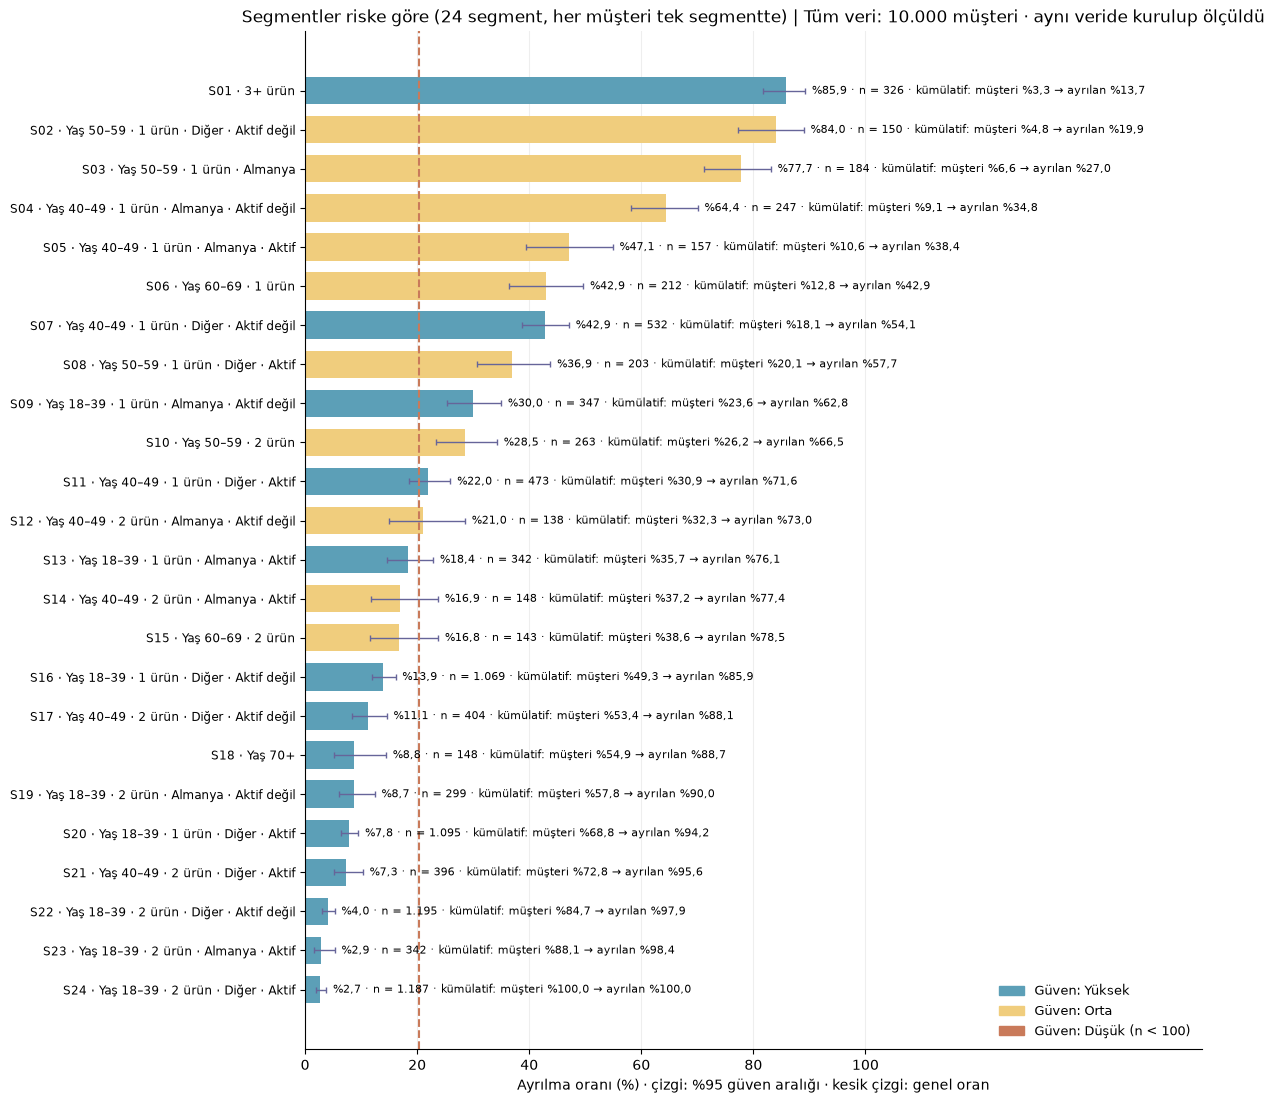

In [18]:
# 5a: segmentasyon (her müşteri tek segmentte), segment tablosu ve grafiği
seg_veri = eda.segment_verisi(veri)
seg_kurallari, seg_atama = eda.segmentasyon_kur(seg_veri)
segmentler, musteri_segment = eda.segment_tablosu(seg_veri, seg_kurallari, seg_atama, cikti_klasoru)
print(f"Segment sayısı: {len(segmentler)} | atanan müşteri: {eda.tr_sayi(len(musteri_segment))}")
display(segmentler.round(1))
eda.segment_grafigi(segmentler, genel_oran, cikti_klasoru);

**Yorum:** Kural 24 segment üretti; en riskli dört segment müşterilerin %9,1'ini, ayrılanların %34,8'ini içeriyor.

- **En riskli segmentler:** 3+ ürün (%85,9; n = 326), 50–59 yaş · 1 ürün · diğer ülkeler · aktif değil (%84,0; n = 150), 50–59 yaş · 1 ürün · Almanya (%77,7; n = 184), 40–49 yaş · 1 ürün · Almanya · aktif değil (%64,4; n = 247).
- **Ortak örüntü:** İlk 10 segmentin 8'i 1 ürünlü müşterilerden oluşuyor; 2 ürünlüler yalnızca 50–59 yaşta (S10, %28,5) ilk 10'a giriyor. Bölüm 4'teki yaş × ürün × aktiflik ve Almanya örüntüsü segmentlerde aynen görülüyor.
- **En düşük riskli:** 18–39 yaş 2 ürünlü dört segment müşterilerin %30,2'sini, ayrılanların yalnızca %5,7'sini içeriyor (%2,7–8,7). 70+ yaş tek segment ve düşük riskli (%8,8).

**Güven:** 24 segmentin 14'ü yüksek, 10'u orta güvenli; kural gereği hiçbir segment 100 müşterinin altında değil. Orta güvenli segmentlerin düzeyi ±5 puandan fazla oynayabilir, bu yüzden sıralamadaki yerleri kesin değil (örneğin S02 ile S03'ün güven aralıkları örtüşüyor).

**Sınır:** Segmentler aynı veride kuruldu ve ölçüldü; oranlar iyimser. Bölme kuralı ayrılma oranına bakmıyor, ama değişkenlerin seçimi ve sırası bu verideki bulgulara dayanıyor.

### 5b. Yakalama eğrisi: kapasiteye göre kaç ayrılan yakalanır?

Segmentler en riskliden başlanarak sıralanır; x ekseni bakılan müşterilerin, y ekseni yakalanan ayrılanların payıdır. Karşılaştırma için: rastgele seçim, yalnızca yaş, yaş × ürün sayısı, aynı dört değişken ve aynı segment sayısıyla kısıtlı bir karar ağacı (CART, yaprakta ≥ 100) ve kusursuz sınır (bütün ayrılanları önce bulmak). Kapasite bir segmentin ortasına düşerse segment içinden rastgele seçim varsayılır. Gerçek kapasite bilinmediği için %10, %20 ve %30 noktaları raporlanır; Power BI'da kaydırıcı olacaktır.

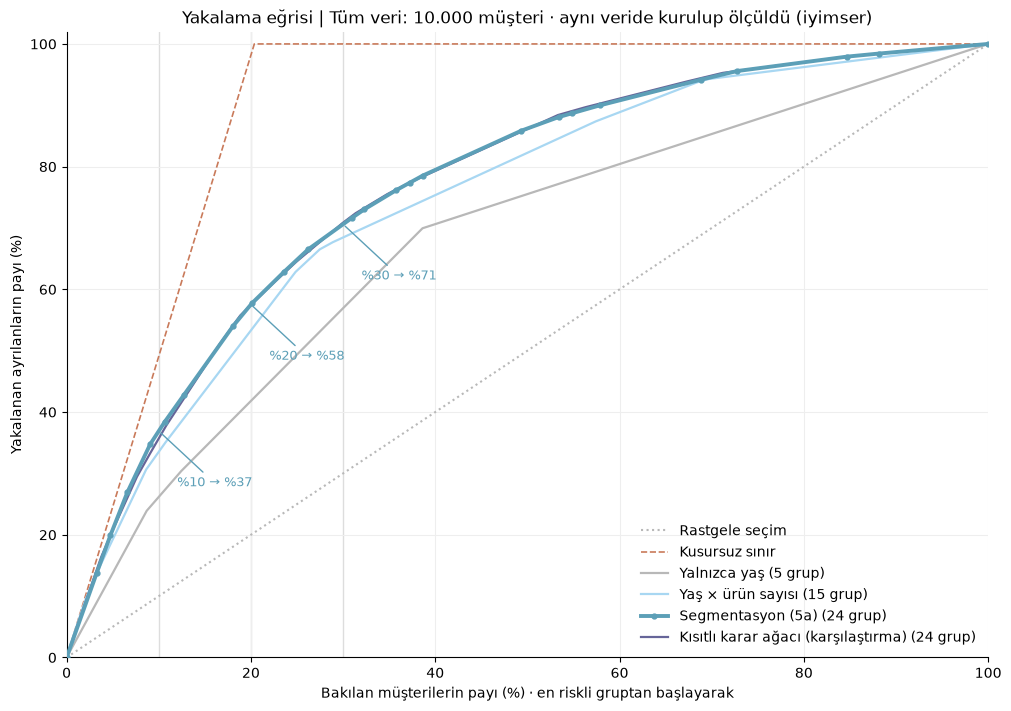

,Yöntem,Grup sayısı,%10 müşteri → yakalanan ayrılan (%),%10 müşteride ayrılma oranı (%),%20 müşteri → yakalanan ayrılan (%),%20 müşteride ayrılma oranı (%),%30 müşteri → yakalanan ayrılan (%),%30 müşteride ayrılma oranı (%)
0,Rastgele seçim,—,10.0,20.4,20.0,20.4,30.0,20.4
1,Yalnızca yaş,5,26.2,53.3,41.8,42.6,56.9,38.7
2,Yaş × ürün sayısı,15,33.5,68.3,53.3,54.3,68.5,46.5
3,Segmentasyon (5a),24,36.9,75.2,57.5,58.6,70.6,47.9
4,Kısıtlı karar ağacı (karşılaştırma),24,35.7,72.7,57.4,58.5,70.9,48.1
5,Kusursuz sınır,—,49.1,100.0,98.2,100.0,100.0,67.9


In [19]:
# 5b: yakalama eğrisi ve kapasite noktalarında yakalanan ayrılan payı
yakalama = eda.yakalama_egrisi(seg_veri, seg_atama, cikti_klasoru)
display(yakalama.round(1))

**Gözlem:** Aynı-veri EDA eğrisinde %10/%20/%30 kapasitede yakalama %36,9/%57,5/%70,6. İlk dilimlerde gözlenen ayrılan yoğunluğu daha yüksek. %20'de kısıtlı ağaç %57,4, elle yazılmış segment kuralı %57,5 veriyor.

**İş anlamı:** Kapasite arttıkça isabet ve kapsamın nasıl değiştiğini gösterir. %20 uygun bir karşılaştırma senaryosudur; maliyet, müdahale etkisi ve bütçe olmadan “en verimli kapasite” seçilmiş sayılmaz.

**Sınır:** Kural ve ağaç aynı veride kurulup ölçüldü; benzer nokta değerleri eşit performans kanıtı değildir. Kusursuz etiket sıralamasına uzaklık, bu özelliklerin ulaşabileceği teorik sınırı göstermez. Bu skorlar gelecekte ayrılma veya müdahaleye yanıt ölçmez.

## 6. Sınırlar, ML'ye taşınanlar ve özet

**Soru:** Bu çalışma neyi gösteriyor, neyi gösteremiyor ve modele ne taşınıyor?

**Yöntem ve gerekçe:** Yeni analiz yapılmaz; Bölüm 1–5'in sonuçları üç başlıkta toplanır. Özetteki sayılar elle yazılmaz, önceki bölümlerin çıktılarından okunur; veri veya kural değişirse özet de güncellenir.

### 6a. Bu çalışma neyi gösterir, neyi gösteremez?

- **Köken/örnekleme belgelenmemiş:** Düzenli dağılımlar yapay üretimi kanıtlamaz. Bulgular gerçek bir bankaya doğrudan genellenmez.
- **Tarih ve iş tanımları eksik:** Gelecek 30/60/90 günlük ayrılma tahmini, para/Tenure birimi veya aktifliğin zamanlaması doğrulanamaz.
- **Keşif tüm veride:** Yaş sınırları, etkileşim fikirleri ve segment tasarımı daha sonra test diye ayrılan müşterileri de gördü. RF'nin ham değişken kullanması tüm proje seçimini bu keşiften bağımsız yapmaz.
- **İlişki ve tahmin, teklif etkisi değildir:** Yüksek skorlu kişinin teklifle kalacağını veya kalmayacağını bu veri göstermez. Etki için kontrollü deney/uygun teklif-sonuç verisi gerekir.
- **Dış geçerlilik ayrı:** Rastgele müşteri ayrımı zamansal, banka dışı veya yeni kategori performansını doğrulamaz. Başka veri üzerinde çalışacağı veya çalışmayacağı peşinen kesinleştirilemez.
- **Değişim:** Müşteri bileşimi ve genel oran değişirse hem olasılıklar hem sıralama bozulabilir; sıralamanın dayanıklı kalacağı garanti değildir. Yeni kategoriler/eksikler açıkça denetlenmelidir.

Taşınabilir olan; veri kalite kontrolü, soru odaklı analiz, kayıtlı yöntem, sayı/aralıkla raporlama ve açık değerlendirme sınırlarıdır.

### 6b. ML'ye taşınan fikirler

Buradaki hiçbir fikir kesin karar değildir; her biri ML aşamasında yalnızca eğitim verisinde veya çapraz doğrulamada sınanır.

| Fikir | Kaynak | ML'de nasıl ele alınacak |
|---|---|---|
| Yaş ile risk ters U biçiminde | 2b | Lojistik regresyonda aralık veya eğri terimi; ağaç modelleri kendiliğinden yakalar |
| Ürün sayısı doğrusal değil (1 yüksek, 2 düşük, 3+ çok yüksek) | 2a | Kategori mi sayı mı: çapraz doğrulamada karşılaştırılır |
| Yaş × aktiflik ve ürün sayısı × bakiye etkileşimleri | 4c, 4d | Lojistik regresyonda etkileşim terimi adayı (odds ölçeğinde korunanlar) |
| Bakiye: sıfır mı ve tutar | 1, 4b | İki ayrı özellik adayı |
| 4 ürün (n = 60), kredi puanı 405 altı (n = 21) | 1, 2b | Özel kural yazılmaz; seyrek gruplara aşırı uyuma dikkat edilir |
| Zayıf değişkenler (Tenure, kredi puanı, gelir, kredi kartı) | 2c | Otomatik çıkarılmaz; özellik kararı eğitimde verilir |
| Aralık sınırları tüm veride seçildi | 2b, 4, 5 | Ham değişkenler kullanılır veya aralıklar eğitimde yeniden belirlenir |
| Cinsiyet ve yaş demografik | 2a, 5 | Cinsiyet ana girdi değildir; performans cinsiyet, yaş ve ülke gruplarına göre ayrıca raporlanır |
| "Aktif değil" belirti olabilir | 6a | ML'ye geçmeden önce kullanıcıyla tartışılacak; seçeneklerden biri modelin bu değişkenle ve bu değişken olmadan karşılaştırılması |
| Kural tabanlı segmentasyon referanstır | 5 | `eda.segmentasyon_kur` eğitim verisinde çalıştırılır, test setinde ölçülür; ML'nin yenmesi gereken rakip |
| Kapasiteye göre ölçüm | 5b | İlk %10 / %20 / %30'da yakalanan ayrılan payı, Average Precision ve Brier; accuracy tek başına kullanılmaz |
| Model raporu dipnotu | 6a | "İlk betimsel analiz tüm veride yapıldı; son test bu keşiften tamamen bağımsız değildir." |

**Güncel durum:** Bu fikirlerin bir kısmı LR özellik tasarımına sabit olarak taşındı. Sınırları eğitimde tekrar kullanmak tüm-veri keşfinin etkisini silmez. Aktiflik ana modelde dışarıda; cinsiyet girdi değil, grup raporlaması içindir. İlk test geçmişte yapıldı; yeni sürüm yalnız eğitim/geliştirmede çalışır.

### 6c. Özet

Aşağıdaki maddelerdeki sayılar Bölüm 2–5'in çıktılarından üretilir (`eda.eda_ozeti`).

In [20]:
# 6c: özet; sayılar önceki bölümlerin çıktılarından okunur
from IPython.display import Markdown
display(Markdown(eda.eda_ozeti(veri, etki, yapraklar, segmentler, yakalama)))

1. **Genel tablo:** 10.000 müşteriden 2.037 kişi ayrılmış; ayrılma oranı %20,37.
2. **En güçlü iki değişken:** yaş (AUC = 0,73) ve ürün sayısı (V = 0,39). Yaş ile risk arasındaki ilişki ters U biçiminde; ürün sayısında en düşük risk 2 üründe.
3. **İki risk tipi:** 3+ ürünlüler küçük ama çok yoğun bir risk (n = 326, oran %85,9); Almanya geniş bir risk havuzu (müşteri payı %25,1, ayrılan payı %40,0, oran %32,4).
4. **Risk kombinasyonlarda yoğunlaşıyor:** Karar ağacına göre en çok ayrılanı içeren grup "Yaş grubu ≠ 18–39 ve Ürün sayısı ≠ 2 ürün ve Aktiflik = Aktif değil" (müşteri payı %12,3, ayrılan payı %38,8, oran %64,2).
5. **Kapasite:** 24 segmentlik kural tabanlı önceliklendirmeyle bakılan müşteri payı → yakalanan ayrılan payı: %10 → %36,9 · %20 → %57,5 · %30 → %70,6. Karşılaştırma: yalnızca yaşa göre sıralamada %20 kapasitede yakalanan pay %41,8.
6. **Sınır:** Bu sayılar aynı veride kurulup ölçüldü; bağımsız tahmin performansı değildir. Bulgular ilişkiseldir, nedensellik veya teklif etkisi göstermez; veri kökeni belgelenmemiştir. İlk EDA tüm verideydi; sonraki test bu keşiften tamamen bağımsız değildir.